# Téléchargement des Données

In [ ]:
import os
%pip install -q kagglehub
import kagglehub

if not os.path.exists("./data"):
    print("Téléchargement du dataset...")
    path = kagglehub.dataset_download(
        "muhammadzakria2001/space-debris-detection-dataset-for-yolov8",
        output_dir="./../data"
    )
    print("Téléchargement terminé :", path)
else:
    print("Le dossier data existe déjà. Aucun téléchargement effectué.")

# Apprentissage multitâche des objets spatiaux

## Pipeline de classification et de boîtes englobantes

Ce notebook poursuit la mission de suivi des objets spatiaux : déterminer si l'objet principal est un satellite ou un debris, puis fournir une boîte permettant de localiser approximativement cet objet dans l'image.

Les onze classes Roboflow sont volontairement simplifiées en deux classes. Cette simplification correspond au besoin opérationnel du projet : détecter un debris et déclencher une vérification, sans exiger une connaissance experte du type exact de chaque satellite. Le notebook apprend donc uniquement une classe binaire et une boîte pour l'objet principal.

Les annotations contiennent une boîte principale par image. Les objets secondaires, petits groupes ou scènes avec plusieurs objets ne sont pas une cible explicite. Le redimensionnement en 224 × 224 facilite l'apprentissage, mais peut atténuer les détails des objets très petits. Les boîtes proches des bords et les formes visuellement ambiguës constituent les cas les plus difficiles.


In [5]:
from pathlib import Path
import sys
import os
# BLOQUE 1 - Configuration, import et matériel
# Charge les bibliothèques, sélectionne GPU/CPU, lit data.yaml et fixe 224x224,
# une taille de lot de 16 et 60 époques pour l'apprentissage multitâche.
import glob
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import tensorflow as tf
import yaml
import logging

from UTILS.logging_settings import setup_logging
from tensorflow import keras
from tensorflow.keras import layers


_cwd = Path.cwd().resolve()
_candidates = [_cwd, _cwd.parent, _cwd / "src"]
PROJECT_ROOT = next((p for p in _candidates if (p / "data").is_dir()), _cwd)
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
logging.info("Répertoire projet utilisé : %s", PROJECT_ROOT)


setup_logging(level=logging.INFO, log_file="log_file", console=True, enable_traceback=True)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 60
MODEL_PATH = "src/models/Class_Detection/satellite_debris_hard_70_retrain_v4.keras"
OUTPUT_PATH = "src/models/BBOX/A_SUPPRIMER.keras"

# Choix possibles : hardcoded, plateau ou cosine_decay.
# Exemple : LEARNING_RATE_MODE=plateau jupyter notebook bounding_box_training.ipynb

LEARNING_RATE_MODE = "cosine_decay"  
INITIAL_LEARNING_RATE = 1e-3



LEARNING_RATE_MODE = {
    "hardcode": "hardcoded",
    "cosine": "cosine_decay",
}.get(LEARNING_RATE_MODE, LEARNING_RATE_MODE)

if LEARNING_RATE_MODE not in {"cosine_decay", "plateau", "hardcoded"}:
    raise ValueError(
        "LEARNING_RATE_MODE doit être 'hardcoded', 'plateau' ou 'cosine_decay'"
    )

GPU_DEVICES = tf.config.list_physical_devices("GPU")
if GPU_DEVICES:
    for gpu in GPU_DEVICES:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
    TRAINING_DEVICE = "/GPU:0"
    logging.info("Entraînement sur GPU : %s", [gpu.name for gpu in GPU_DEVICES])
else:
    TRAINING_DEVICE = "/CPU:0"
    logging.warning("Aucun GPU détecté : entraînement sur CPU")

with open("data/data.yaml", "r", encoding="utf-8") as yaml_file:
    dataset_config = yaml.safe_load(yaml_file)

ORIGINAL_CLASS_NAMES = dataset_config["names"]
CLASS_NAMES = ["satellite", "debris"]
logging.info("TensorFlow : %s", tf.__version__)
logging.info("Classes originales : %s", ORIGINAL_CLASS_NAMES)
logging.info("Classes du modèle : %s", CLASS_NAMES)

2026-11-25 10:37:32 [INFO] : root : Répertoire projet utilisé : /home/jzory/Documents/leo
2026-11-25 10:37:32 [INFO] : root : Entraînement sur GPU : ['/physical_device:GPU:0']
2026-11-25 10:37:32 [INFO] : root : TensorFlow : 2.21.0
2026-11-25 10:37:32 [INFO] : root : Classes originales : ['cheops', 'debris', 'double_start', 'earth_observation_sat_1', 'lisa_pathfinder', 'proba_2', 'proba_3_csc', 'proba_3_ocs', 'smart_1', 'soho', 'xmm_newton']
2026-11-25 10:37:32 [INFO] : root : Classes du modèle : ['satellite', 'debris']


## 1. Préparation des données

### 1.1. Lecture des annotations YOLO

Chaque image du dataset est liée à un fichier texte. Chaque ligne contient :

```text
class_id x_center y_center width height
```

Les coordonnées sont normalisées entre 0 et 1. Dans ce dataset, une image contient un objet principal. Le code prend donc la première ligne et ignore volontairement toute annotation secondaire éventuelle.

In [6]:
# BLOQUE 2 - DataFrame des boîtes et classes
# Chaque exemple associe maintenant un chemin d'image, une classe binaire et quatre
# coordonnées normalisées converties du format YOLO vers [ymin, xmin, ymax, xmax].
def create_dataset_dataframe(image_dir):
    records = []
    image_paths = sorted(glob.glob(os.path.join(image_dir, "*.jpg")))

    for image_path in image_paths:
        label_path = image_path.replace("images", "labels").replace(".jpg", ".txt")
        if not os.path.exists(label_path):
            continue

        with open(label_path, "r", encoding="utf-8") as label_file:
            line = label_file.readline().strip()
        if not line:
            continue

        parts = line.split()
        if len(parts) != 5:
            raise ValueError(f"Label YOLO invalide : {label_path}")

        class_id = int(parts[0])
        x_center, y_center, width, height = map(float, parts[1:])
        class_name = ORIGINAL_CLASS_NAMES[class_id]
        ymin = max(0.0, y_center - height / 2.0)
        xmin = max(0.0, x_center - width / 2.0)
        ymax = min(1.0, y_center + height / 2.0)
        xmax = min(1.0, x_center + width / 2.0)

        binary_class_id = int(class_name == "debris")
        records.append({
            "image_path": image_path,
            "binary_class_id": binary_class_id,
            "binary_class_name": CLASS_NAMES[binary_class_id],
            "ymin": ymin,
            "xmin": xmin,
            "ymax": ymax,
            "xmax": xmax,
        })

    return pd.DataFrame(records)

df_train = create_dataset_dataframe("data/train/images")
df_val = create_dataset_dataframe("data/valid/images")
df_test = create_dataset_dataframe("data/test/images")
logging.info("Train : %d images", len(df_train))
logging.info("Val   : %d images", len(df_val))
logging.info("Test  : %d images", len(df_test))
logging.info("Répartition train :\n%s", df_train["binary_class_name"].value_counts())
df_train.head()

2026-11-25 10:37:32 [INFO] : root : Train : 2105 images
2026-11-25 10:37:32 [INFO] : root : Val   : 239 images
2026-11-25 10:37:32 [INFO] : root : Test  : 123 images
2026-11-25 10:37:32 [INFO] : root : Répartition train :
binary_class_name
satellite    1919
debris        186
Name: count, dtype: int64


,image_path,binary_class_id,binary_class_name,ymin,xmin,ymax,xmax
0,data/train/images/img000008_jpg.rf.2c95cb6fb03...,0,satellite,0.369141,0.129297,0.865234,0.430078
1,data/train/images/img000008_jpg.rf.9f76dc15cc1...,0,satellite,0.134766,0.129297,0.630859,0.430078
2,data/train/images/img000009_jpg.rf.1142d9cc183...,0,satellite,0.341016,0.192578,0.969922,0.585547
3,data/train/images/img000009_jpg.rf.1c26d8ebd8e...,0,satellite,0.341016,0.414453,0.969922,0.807422
4,data/train/images/img000009_jpg.rf.da7b45fe680...,0,satellite,0.030078,0.192578,0.658984,0.585547


In [7]:
# BLOQUE 3 - Dataset TensorFlow multitâche
# Cette cellule produit pour chaque lot les entrées image et les sorties nommées
# class_output et bbox_output. Le jeu d'entraînement est mélangé uniquement.
def df_to_multitask_dataset(df, is_training):
    image_paths = df["image_path"].values
    boxes = df[["ymin", "xmin", "ymax", "xmax"]].values.astype(np.float32)
    class_ids = df["binary_class_id"].values.astype(np.float32)
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, boxes, class_ids))

    def load_and_preprocess(image_path, box, class_id):
        image = tf.io.read_file(image_path)
        image = tf.image.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
        image = keras.applications.mobilenet_v2.preprocess_input(image)
        return image, {
            "class_output": tf.expand_dims(class_id, axis=-1),
            "bbox_output": box,
        }

    if is_training:
        dataset = dataset.shuffle(min(len(df), 1000), reshuffle_each_iteration=True)
    return dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = df_to_multitask_dataset(df_train, is_training=True)
val_ds = df_to_multitask_dataset(df_val, is_training=False)
test_ds = df_to_multitask_dataset(df_test, is_training=False)

## 2. Construction du modèle multitâche

### 2.1. Réutilisation du backbone MobileNetV2

Le modèle de classification sélectionné sert de point de départ. Son backbone MobileNetV2 est retrouvé par son nom, dégelé puis réutilisé dans un nouveau modèle. Les caractéristiques extraites alimentent deux têtes indépendantes :

- une tête sigmoïde de probabilité de debris ;
- une tête sigmoïde de quatre coordonnées normalisées.

Cette stratégie de transfert permet de partir d'une représentation déjà adaptée aux images astronomiques du dataset plutôt que d'initialiser toute l'architecture.

## 2.2. Évaluation de la qualité des boîtes

La MAE mesure l'écart moyen des quatre coordonnées. Elle est facile à optimiser mais peut être faible même si la boîte est mal placée globalement.

L'IoU mesure l'intersection divisée par l'union des boîtes vraie et prédite. Une boîte est considérée correcte lorsque son IoU est supérieure ou égale à 0.5. Cette métrique correspond davantage à la qualité visuelle d'une détection.

In [8]:
# BLOQUE 4 - Architecture, IoU et compilation
# Le backbone MobileNetV2 du modèle de classification alimente deux têtes : une
# sigmoïde pour la classe et une sigmoïde à quatre valeurs pour la boîte.
# Huber, IoU et accuracy des boîtes sont reliés aux objectifs du projet.
old_model = keras.models.load_model(MODEL_PATH, compile=False)
backbone = old_model.get_layer("mobilenetv2_1.00_224")
backbone.trainable = True

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
features = backbone(inputs, training=False)
features = layers.GlobalAveragePooling2D()(features)
features = layers.Dropout(0.2)(features)

class_output = layers.Dense(1, activation="sigmoid", name="class_output")(features)
bbox_output = layers.Dense(4, activation="sigmoid", name="bbox_output")(features)

model = keras.Model(
    inputs=inputs,
    outputs={"class_output": class_output, "bbox_output": bbox_output},
)

# Une boîte prédite est jugée correcte si son IoU avec la vraie boîte atteint ce seuil
IOU_THRESHOLD = 0.5

def iou(y_true, y_pred):
    # Boîtes au format [ymin, xmin, ymax, xmax], normalisées entre 0 et 1
    inter_ymin = keras.ops.maximum(y_true[..., 0], y_pred[..., 0])
    inter_xmin = keras.ops.maximum(y_true[..., 1], y_pred[..., 1])
    inter_ymax = keras.ops.minimum(y_true[..., 2], y_pred[..., 2])
    inter_xmax = keras.ops.minimum(y_true[..., 3], y_pred[..., 3])
    intersection = (
        keras.ops.maximum(0.0, inter_ymax - inter_ymin)
        * keras.ops.maximum(0.0, inter_xmax - inter_xmin)
    )
    true_area = (y_true[..., 2] - y_true[..., 0]) * (y_true[..., 3] - y_true[..., 1])
    # Les 4 sorties sont indépendantes : une boîte prédite peut être "retournée"
    # (ymax < ymin), on lui donne alors une aire nulle.
    pred_area = (
        keras.ops.maximum(0.0, y_pred[..., 2] - y_pred[..., 0])
        * keras.ops.maximum(0.0, y_pred[..., 3] - y_pred[..., 1])
    )
    union = true_area + pred_area - intersection
    return intersection / (union + 1e-7)

def box_accuracy(y_true, y_pred):
    # 1 si la boîte est bonne (IoU >= seuil), 0 sinon : la moyenne Keras
    # donne le ratio boîtes bonnes / nombre total de boîtes
    return keras.ops.cast(iou(y_true, y_pred) >= IOU_THRESHOLD, "float32")

def compile_multitask_model(model, learning_rate=INITIAL_LEARNING_RATE):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss={
            "class_output": keras.losses.BinaryCrossentropy(),
            "bbox_output": keras.losses.Huber(),
        },
        loss_weights={"class_output": 1.0, "bbox_output": 5.0},
        metrics={
            "class_output": [keras.metrics.BinaryAccuracy(name="accuracy")],
            "bbox_output": [keras.metrics.MeanAbsoluteError(name="mae"), iou, box_accuracy],
        },
    )

if LEARNING_RATE_MODE == "cosine_decay":
    # Nombre exact de batches par epoch (le dernier batch incomplet est conservé)
    total_steps = len(train_ds) * EPOCHS
    learning_rate = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=INITIAL_LEARNING_RATE,
        decay_steps=total_steps,
        alpha=1e-2,
    )
else:
    # Utilisé directement pour le mode hardcoded et comme valeur initiale
    # lorsque ReduceLROnPlateau ajuste le taux pendant l'entraînement.
    learning_rate = INITIAL_LEARNING_RATE

compile_multitask_model(model, learning_rate)
logging.info(
    f"Mode du learning rate : {LEARNING_RATE_MODE} "
    f"(initial={INITIAL_LEARNING_RATE:f}, epochs={EPOCHS})"
)
model.summary()

2026-11-25 10:37:34 [INFO] : root : Mode du learning rate : cosine_decay (initial=0.001000, epochs=60)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ image_input[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox_output (Dense) │ (None, 4)         │      5,124 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 1)         │      1,281 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 2,230,277 (8.51 MB)

 Non-trainable params: 34,112 (133.25 KB)

## 3. Entraînement multitâche

Le modèle apprend simultanément deux objectifs :

- la perte de classe par entropie croisée binaire ;
- la perte de coordonnées par Huber, pondérée cinq fois plus fortement que la classe.

Le poids supérieur accordé aux boîtes vient du choix du projet : les deux sorties doivent apprendre ensemble, mais la correction géométrique doit avoir une influence suffisante. Les augmentations aléatoires ne sont pas activées dans ce notebook, car elles devraient aussi transformer les coordonnées de la boîte.

Epoch 1/60


/home/jzory/Documents/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795599461.674433  383087 service.cc:153] XLA service 0x71e868096fa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795599461.674446  383087 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5090, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795599461.883475  383087 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795599463.125731  383087 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1795599463.332004  383087 dot_merger.cc:481] Merging

  7/132 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - bbox_output_box_accuracy: 0.0714 - bbox_output_iou: 0.2035 - bbox_output_loss: 0.0226 - bbox_output_mae: 0.1753 - class_output_accuracy: 0.9732 - class_output_loss: 0.1816 - loss: 0.2947

I0000 00:00:1795599491.790708  383087 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - bbox_output_box_accuracy: 0.2343 - bbox_output_iou: 0.3425 - bbox_output_loss: 0.0122 - bbox_output_mae: 0.1226 - class_output_accuracy: 0.9900 - class_output_loss: 0.0392 - loss: 0.1003

I0000 00:00:1795599495.657269  383083 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_34046__.329
E0000 00:00:1795599496.612666  383083 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795599496.761611  383083 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795599499.347381  383083 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - bbox_output_box_accuracy: 0.2347 - bbox_output_iou: 0.3428 - bbox_output_loss: 0.0122 - bbox_output_mae: 0.1225 - class_output_accuracy: 0.9900 - class_output_loss: 0.0391 - loss: 0.1001

E0000 00:00:1795599523.819021  383087 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795599528.004526  383087 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795599528.198738  383087 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795599532.980376  383094 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795599538.334807  383094 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-

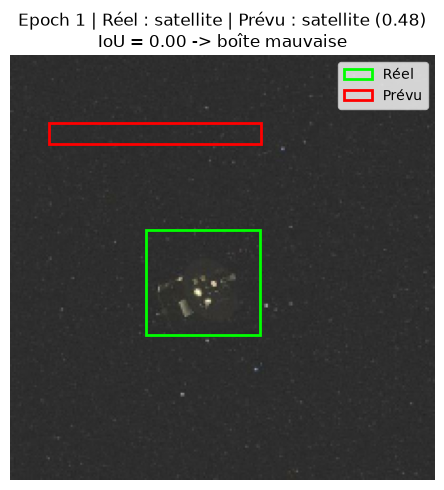

132/132 ━━━━━━━━━━━━━━━━━━━━ 85s 365ms/step - bbox_output_box_accuracy: 0.2347 - bbox_output_iou: 0.3428 - bbox_output_loss: 0.0122 - bbox_output_mae: 0.1225 - class_output_accuracy: 0.9900 - class_output_loss: 0.0391 - loss: 0.1001 - val_bbox_output_box_accuracy: 0.0000e+00 - val_bbox_output_iou: 0.0148 - val_bbox_output_loss: 0.0618 - val_bbox_output_mae: 0.2883 - val_class_output_accuracy: 0.4226 - val_class_output_loss: 2.7269 - val_loss: 3.0080
Epoch 2/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.3562 - bbox_output_iou: 0.4082 - bbox_output_loss: 0.0083 - bbox_output_mae: 0.0997 - class_output_accuracy: 0.9957 - class_output_loss: 0.0138 - loss: 0.0552

2026-11-25 10:39:02 [INFO] : root : Epoch 2 - Réel : satellite | Prévu : debris (p_debris=0.64) | IoU=0.34 -> boîte mauvaise


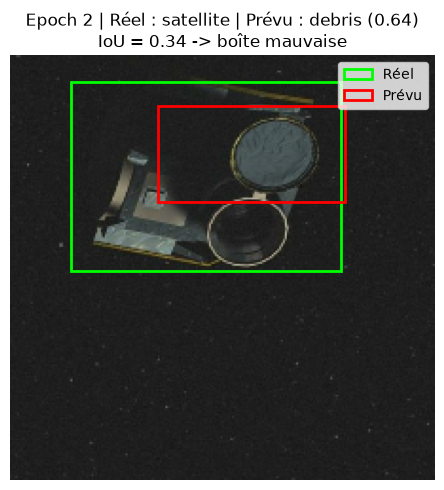

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.3563 - bbox_output_iou: 0.4080 - bbox_output_loss: 0.0083 - bbox_output_mae: 0.0997 - class_output_accuracy: 0.9957 - class_output_loss: 0.0136 - loss: 0.0550 - val_bbox_output_box_accuracy: 0.1172 - val_bbox_output_iou: 0.2639 - val_bbox_output_loss: 0.0212 - val_bbox_output_mae: 0.1676 - val_class_output_accuracy: 0.2385 - val_class_output_loss: 6.6861 - val_loss: 6.7724
Epoch 3/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - bbox_output_box_accuracy: 0.4242 - bbox_output_iou: 0.4340 - bbox_output_loss: 0.0071 - bbox_output_mae: 0.0919 - class_output_accuracy: 0.9924 - class_output_loss: 0.0164 - loss: 0.0519

2026-11-25 10:39:05 [INFO] : root : Epoch 3 - Réel : satellite | Prévu : satellite (p_debris=0.08) | IoU=0.07 -> boîte mauvaise


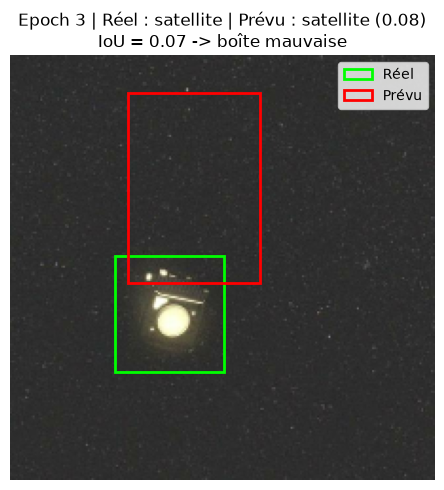

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.4242 - bbox_output_iou: 0.4340 - bbox_output_loss: 0.0071 - bbox_output_mae: 0.0919 - class_output_accuracy: 0.9924 - class_output_loss: 0.0164 - loss: 0.0519 - val_bbox_output_box_accuracy: 0.0544 - val_bbox_output_iou: 0.1850 - val_bbox_output_loss: 0.0290 - val_bbox_output_mae: 0.1893 - val_class_output_accuracy: 0.4686 - val_class_output_loss: 3.6029 - val_loss: 3.7285
Epoch 4/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.5157 - bbox_output_iou: 0.4776 - bbox_output_loss: 0.0054 - bbox_output_mae: 0.0798 - class_output_accuracy: 0.9986 - class_output_loss: 0.0057 - loss: 0.0329

2026-11-25 10:39:07 [INFO] : root : Epoch 4 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.00 -> boîte mauvaise


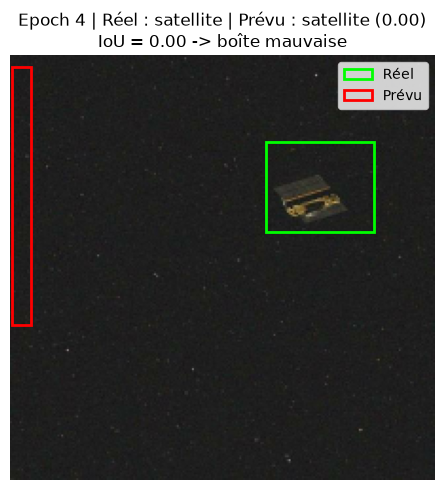

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.5159 - bbox_output_iou: 0.4777 - bbox_output_loss: 0.0054 - bbox_output_mae: 0.0797 - class_output_accuracy: 0.9986 - class_output_loss: 0.0057 - loss: 0.0328 - val_bbox_output_box_accuracy: 0.0000e+00 - val_bbox_output_iou: 0.0130 - val_bbox_output_loss: 0.0801 - val_bbox_output_mae: 0.3258 - val_class_output_accuracy: 0.5607 - val_class_output_loss: 4.1947 - val_loss: 4.5690
Epoch 5/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.5562 - bbox_output_iou: 0.4903 - bbox_output_loss: 0.0050 - bbox_output_mae: 0.0761 - class_output_accuracy: 0.9986 - class_output_loss: 0.0087 - loss: 0.0335

2026-11-25 10:39:10 [INFO] : root : Epoch 5 - Réel : satellite | Prévu : debris (p_debris=0.95) | IoU=0.00 -> boîte mauvaise


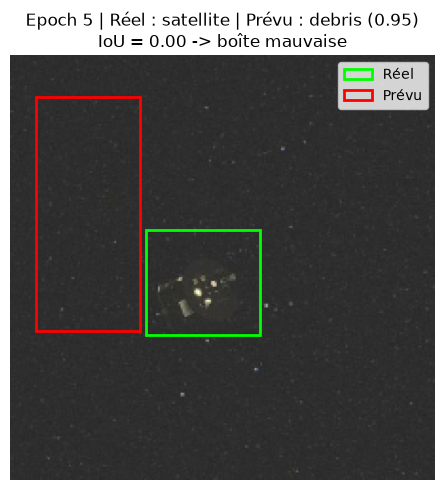

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - bbox_output_box_accuracy: 0.5558 - bbox_output_iou: 0.4903 - bbox_output_loss: 0.0050 - bbox_output_mae: 0.0761 - class_output_accuracy: 0.9986 - class_output_loss: 0.0086 - loss: 0.0334 - val_bbox_output_box_accuracy: 0.0084 - val_bbox_output_iou: 0.0290 - val_bbox_output_loss: 0.0754 - val_bbox_output_mae: 0.3225 - val_class_output_accuracy: 0.4310 - val_class_output_loss: 3.7530 - val_loss: 4.1269
Epoch 6/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.5429 - bbox_output_iou: 0.4846 - bbox_output_loss: 0.0052 - bbox_output_mae: 0.0774 - class_output_accuracy: 0.9967 - class_output_loss: 0.0102 - loss: 0.0361

2026-11-25 10:39:12 [INFO] : root : Epoch 6 - Réel : satellite | Prévu : debris (p_debris=1.00) | IoU=0.00 -> boîte mauvaise


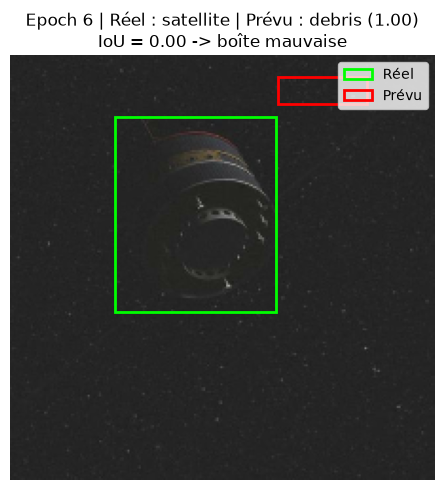

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.5420 - bbox_output_iou: 0.4848 - bbox_output_loss: 0.0052 - bbox_output_mae: 0.0774 - class_output_accuracy: 0.9967 - class_output_loss: 0.0102 - loss: 0.0360 - val_bbox_output_box_accuracy: 0.0042 - val_bbox_output_iou: 0.0277 - val_bbox_output_loss: 0.0709 - val_bbox_output_mae: 0.3062 - val_class_output_accuracy: 0.1172 - val_class_output_loss: 22.4491 - val_loss: 22.7705
Epoch 7/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.5183 - bbox_output_iou: 0.4809 - bbox_output_loss: 0.0052 - bbox_output_mae: 0.0779 - class_output_accuracy: 0.9957 - class_output_loss: 0.0140 - loss: 0.0396

2026-11-25 10:39:15 [INFO] : root : Epoch 7 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.06 -> boîte mauvaise


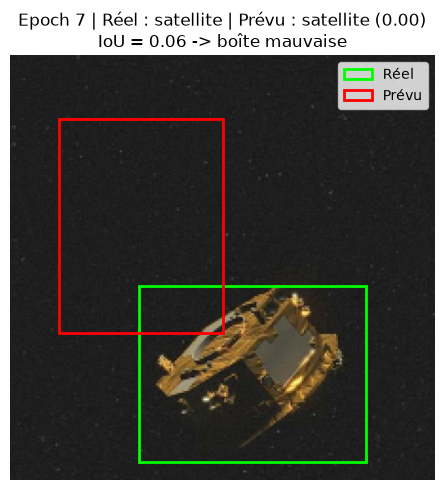

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.5183 - bbox_output_iou: 0.4809 - bbox_output_loss: 0.0052 - bbox_output_mae: 0.0779 - class_output_accuracy: 0.9957 - class_output_loss: 0.0140 - loss: 0.0396 - val_bbox_output_box_accuracy: 0.1130 - val_bbox_output_iou: 0.2214 - val_bbox_output_loss: 0.0304 - val_bbox_output_mae: 0.1957 - val_class_output_accuracy: 0.9079 - val_class_output_loss: 1.8636 - val_loss: 2.0236
Epoch 8/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.5365 - bbox_output_iou: 0.4811 - bbox_output_loss: 0.0054 - bbox_output_mae: 0.0790 - class_output_accuracy: 0.9942 - class_output_loss: 0.0183 - loss: 0.0454

2026-11-25 10:39:17 [INFO] : root : Epoch 8 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.00 -> boîte mauvaise


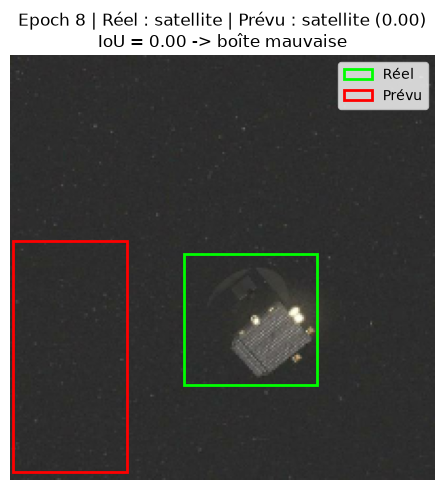

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - bbox_output_box_accuracy: 0.5359 - bbox_output_iou: 0.4810 - bbox_output_loss: 0.0054 - bbox_output_mae: 0.0790 - class_output_accuracy: 0.9943 - class_output_loss: 0.0180 - loss: 0.0451 - val_bbox_output_box_accuracy: 0.0335 - val_bbox_output_iou: 0.1655 - val_bbox_output_loss: 0.0384 - val_bbox_output_mae: 0.2261 - val_class_output_accuracy: 0.9289 - val_class_output_loss: 0.5684 - val_loss: 0.7632
Epoch 9/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.5891 - bbox_output_iou: 0.5122 - bbox_output_loss: 0.0043 - bbox_output_mae: 0.0705 - class_output_accuracy: 0.9971 - class_output_loss: 0.0068 - loss: 0.0284

2026-11-25 10:39:20 [INFO] : root : Epoch 9 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.13 -> boîte mauvaise


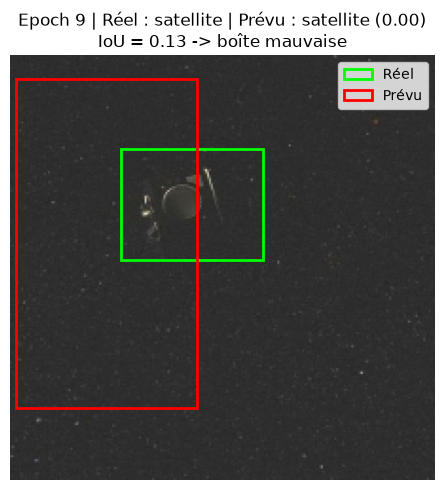

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.5891 - bbox_output_iou: 0.5124 - bbox_output_loss: 0.0043 - bbox_output_mae: 0.0706 - class_output_accuracy: 0.9971 - class_output_loss: 0.0070 - loss: 0.0286 - val_bbox_output_box_accuracy: 0.0921 - val_bbox_output_iou: 0.2262 - val_bbox_output_loss: 0.0344 - val_bbox_output_mae: 0.2102 - val_class_output_accuracy: 0.9247 - val_class_output_loss: 0.7732 - val_loss: 0.9484
Epoch 10/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.5981 - bbox_output_iou: 0.5165 - bbox_output_loss: 0.0042 - bbox_output_mae: 0.0692 - class_output_accuracy: 0.9990 - class_output_loss: 0.0049 - loss: 0.0255

2026-11-25 10:39:23 [INFO] : root : Epoch 10 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.24 -> boîte mauvaise


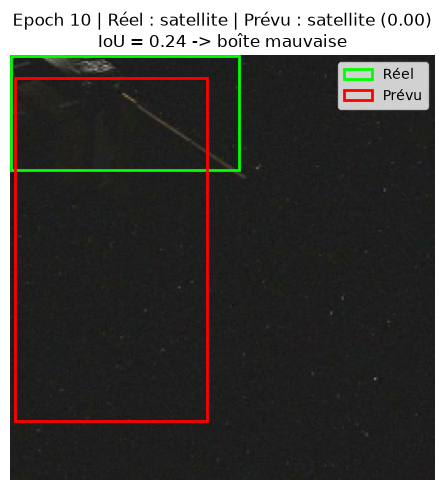

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.5981 - bbox_output_iou: 0.5165 - bbox_output_loss: 0.0042 - bbox_output_mae: 0.0692 - class_output_accuracy: 0.9990 - class_output_loss: 0.0049 - loss: 0.0255 - val_bbox_output_box_accuracy: 0.0293 - val_bbox_output_iou: 0.1963 - val_bbox_output_loss: 0.0365 - val_bbox_output_mae: 0.2198 - val_class_output_accuracy: 0.9623 - val_class_output_loss: 0.3497 - val_loss: 0.5334
Epoch 11/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.6636 - bbox_output_iou: 0.5441 - bbox_output_loss: 0.0034 - bbox_output_mae: 0.0627 - class_output_accuracy: 0.9995 - class_output_loss: 0.0016 - loss: 0.0187

2026-11-25 10:39:25 [INFO] : root : Epoch 11 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.22 -> boîte mauvaise


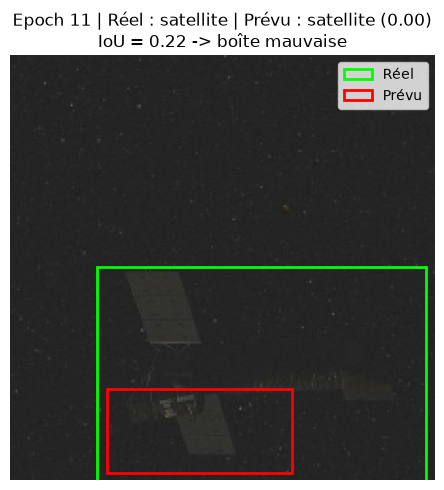

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.6632 - bbox_output_iou: 0.5441 - bbox_output_loss: 0.0034 - bbox_output_mae: 0.0627 - class_output_accuracy: 0.9995 - class_output_loss: 0.0016 - loss: 0.0187 - val_bbox_output_box_accuracy: 0.1632 - val_bbox_output_iou: 0.3087 - val_bbox_output_loss: 0.0189 - val_bbox_output_mae: 0.1492 - val_class_output_accuracy: 0.9540 - val_class_output_loss: 0.3322 - val_loss: 0.4284
Epoch 12/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.7087 - bbox_output_iou: 0.5717 - bbox_output_loss: 0.0030 - bbox_output_mae: 0.0575 - class_output_accuracy: 1.0000 - class_output_loss: 6.0536e-04 - loss: 0.0154

2026-11-25 10:39:28 [INFO] : root : Epoch 12 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.34 -> boîte mauvaise


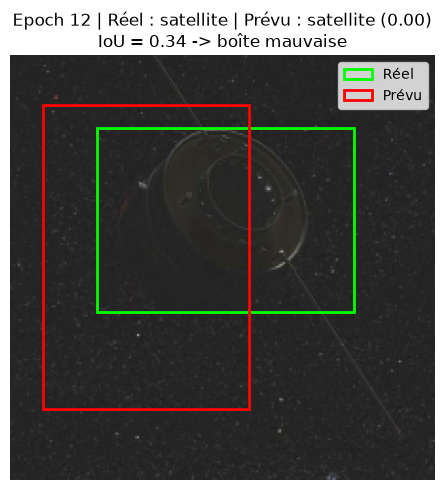

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.7102 - bbox_output_iou: 0.5723 - bbox_output_loss: 0.0029 - bbox_output_mae: 0.0575 - class_output_accuracy: 1.0000 - class_output_loss: 5.9822e-04 - loss: 0.0153 - val_bbox_output_box_accuracy: 0.1255 - val_bbox_output_iou: 0.2981 - val_bbox_output_loss: 0.0166 - val_bbox_output_mae: 0.1415 - val_class_output_accuracy: 0.9707 - val_class_output_loss: 0.1798 - val_loss: 0.2635
Epoch 13/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.7298 - bbox_output_iou: 0.5762 - bbox_output_loss: 0.0028 - bbox_output_mae: 0.0563 - class_output_accuracy: 1.0000 - class_output_loss: 3.7115e-04 - loss: 0.0145

2026-11-25 10:39:31 [INFO] : root : Epoch 13 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.29 -> boîte mauvaise


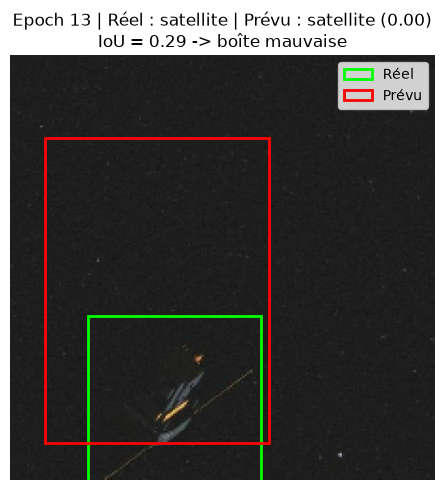

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.7311 - bbox_output_iou: 0.5767 - bbox_output_loss: 0.0028 - bbox_output_mae: 0.0563 - class_output_accuracy: 1.0000 - class_output_loss: 3.6776e-04 - loss: 0.0145 - val_bbox_output_box_accuracy: 0.2343 - val_bbox_output_iou: 0.3548 - val_bbox_output_loss: 0.0129 - val_bbox_output_mae: 0.1229 - val_class_output_accuracy: 0.9833 - val_class_output_loss: 0.0967 - val_loss: 0.1615
Epoch 14/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.7487 - bbox_output_iou: 0.5888 - bbox_output_loss: 0.0026 - bbox_output_mae: 0.0537 - class_output_accuracy: 1.0000 - class_output_loss: 5.0701e-04 - loss: 0.0133

2026-11-25 10:39:34 [INFO] : root : Epoch 14 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.43 -> boîte mauvaise


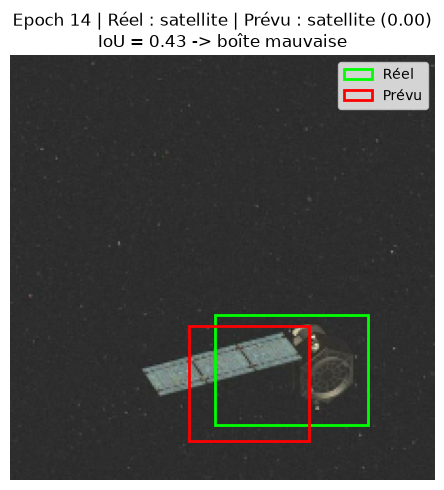

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - bbox_output_box_accuracy: 0.7487 - bbox_output_iou: 0.5888 - bbox_output_loss: 0.0026 - bbox_output_mae: 0.0537 - class_output_accuracy: 1.0000 - class_output_loss: 5.0701e-04 - loss: 0.0133 - val_bbox_output_box_accuracy: 0.3389 - val_bbox_output_iou: 0.4135 - val_bbox_output_loss: 0.0072 - val_bbox_output_mae: 0.0927 - val_class_output_accuracy: 0.9874 - val_class_output_loss: 0.0823 - val_loss: 0.1188
Epoch 15/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.7667 - bbox_output_iou: 0.5989 - bbox_output_loss: 0.0024 - bbox_output_mae: 0.0520 - class_output_accuracy: 1.0000 - class_output_loss: 3.1922e-04 - loss: 0.0123

2026-11-25 10:39:36 [INFO] : root : Epoch 15 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.33 -> boîte mauvaise


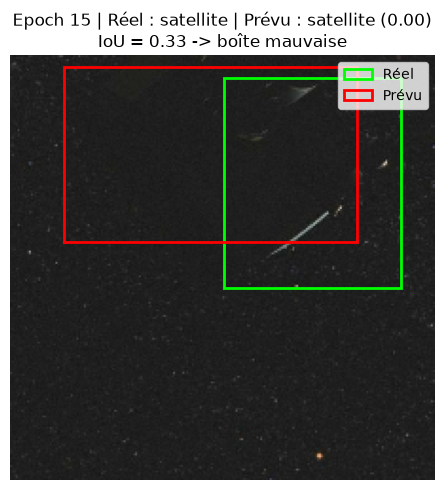

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.7667 - bbox_output_iou: 0.5990 - bbox_output_loss: 0.0024 - bbox_output_mae: 0.0520 - class_output_accuracy: 1.0000 - class_output_loss: 3.1744e-04 - loss: 0.0123 - val_bbox_output_box_accuracy: 0.4644 - val_bbox_output_iou: 0.4459 - val_bbox_output_loss: 0.0065 - val_bbox_output_mae: 0.0866 - val_class_output_accuracy: 0.9916 - val_class_output_loss: 0.0607 - val_loss: 0.0931
Epoch 16/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.7857 - bbox_output_iou: 0.6094 - bbox_output_loss: 0.0023 - bbox_output_mae: 0.0500 - class_output_accuracy: 1.0000 - class_output_loss: 3.4793e-04 - loss: 0.0116

2026-11-25 10:39:39 [INFO] : root : Epoch 16 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.69 -> boîte bonne


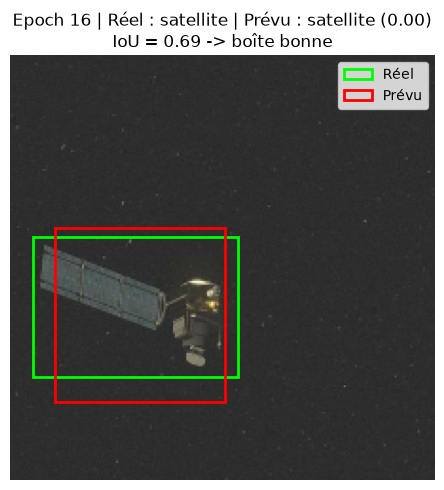

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.7857 - bbox_output_iou: 0.6094 - bbox_output_loss: 0.0023 - bbox_output_mae: 0.0500 - class_output_accuracy: 1.0000 - class_output_loss: 3.4793e-04 - loss: 0.0116 - val_bbox_output_box_accuracy: 0.6067 - val_bbox_output_iou: 0.5166 - val_bbox_output_loss: 0.0043 - val_bbox_output_mae: 0.0695 - val_class_output_accuracy: 0.9916 - val_class_output_loss: 0.0521 - val_loss: 0.0739
Epoch 17/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.7776 - bbox_output_iou: 0.6098 - bbox_output_loss: 0.0022 - bbox_output_mae: 0.0496 - class_output_accuracy: 1.0000 - class_output_loss: 3.3996e-04 - loss: 0.0114

2026-11-25 10:39:42 [INFO] : root : Epoch 17 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.66 -> boîte bonne


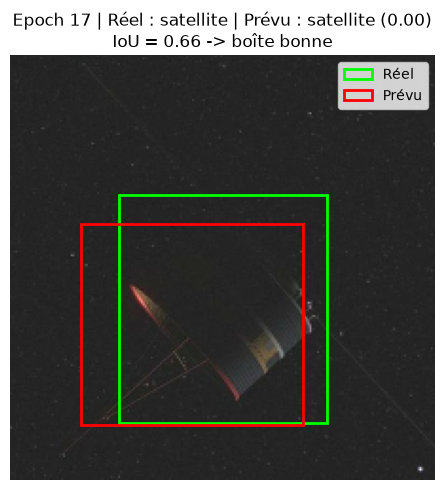

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.7805 - bbox_output_iou: 0.6105 - bbox_output_loss: 0.0022 - bbox_output_mae: 0.0495 - class_output_accuracy: 1.0000 - class_output_loss: 3.3561e-04 - loss: 0.0114 - val_bbox_output_box_accuracy: 0.5063 - val_bbox_output_iou: 0.4655 - val_bbox_output_loss: 0.0053 - val_bbox_output_mae: 0.0802 - val_class_output_accuracy: 0.9916 - val_class_output_loss: 0.0519 - val_loss: 0.0786
Epoch 18/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - bbox_output_box_accuracy: 0.8092 - bbox_output_iou: 0.6222 - bbox_output_loss: 0.0020 - bbox_output_mae: 0.0476 - class_output_accuracy: 1.0000 - class_output_loss: 2.2508e-04 - loss: 0.0103

2026-11-25 10:39:45 [INFO] : root : Epoch 18 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.53 -> boîte bonne


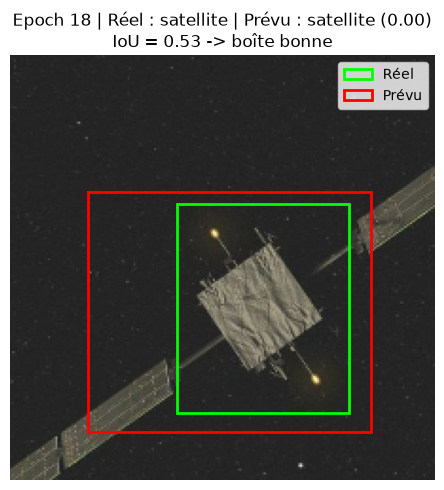

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.8067 - bbox_output_iou: 0.6213 - bbox_output_loss: 0.0020 - bbox_output_mae: 0.0477 - class_output_accuracy: 1.0000 - class_output_loss: 2.2383e-04 - loss: 0.0103 - val_bbox_output_box_accuracy: 0.5900 - val_bbox_output_iou: 0.4957 - val_bbox_output_loss: 0.0043 - val_bbox_output_mae: 0.0706 - val_class_output_accuracy: 0.9916 - val_class_output_loss: 0.0459 - val_loss: 0.0678
Epoch 19/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.8048 - bbox_output_iou: 0.6253 - bbox_output_loss: 0.0020 - bbox_output_mae: 0.0470 - class_output_accuracy: 1.0000 - class_output_loss: 1.9053e-04 - loss: 0.0100

2026-11-25 10:39:47 [INFO] : root : Epoch 19 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.82 -> boîte bonne


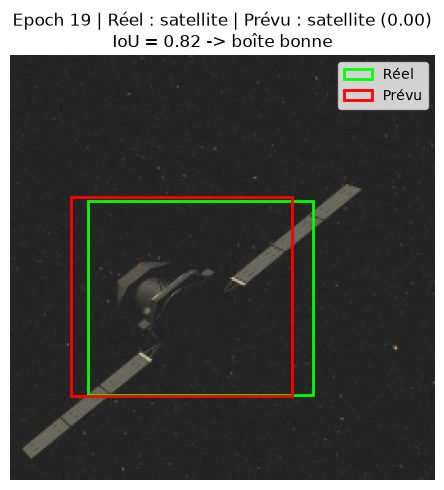

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.8057 - bbox_output_iou: 0.6255 - bbox_output_loss: 0.0020 - bbox_output_mae: 0.0469 - class_output_accuracy: 1.0000 - class_output_loss: 1.8988e-04 - loss: 0.0100 - val_bbox_output_box_accuracy: 0.6485 - val_bbox_output_iou: 0.5368 - val_bbox_output_loss: 0.0034 - val_bbox_output_mae: 0.0631 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0418 - val_loss: 0.0590
Epoch 20/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8245 - bbox_output_iou: 0.6357 - bbox_output_loss: 0.0018 - bbox_output_mae: 0.0453 - class_output_accuracy: 1.0000 - class_output_loss: 1.6550e-04 - loss: 0.0094

2026-11-25 10:39:50 [INFO] : root : Epoch 20 - Réel : debris | Prévu : debris (p_debris=1.00) | IoU=0.09 -> boîte mauvaise


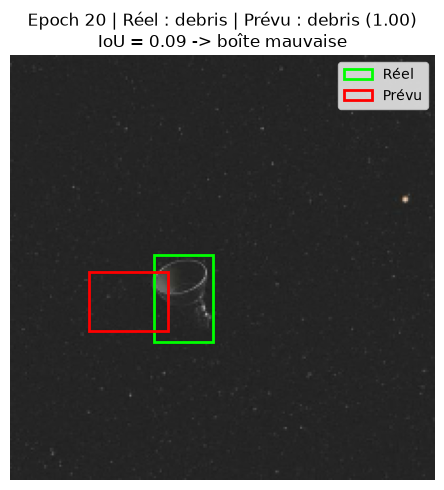

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.8252 - bbox_output_iou: 0.6356 - bbox_output_loss: 0.0018 - bbox_output_mae: 0.0453 - class_output_accuracy: 1.0000 - class_output_loss: 1.6391e-04 - loss: 0.0094 - val_bbox_output_box_accuracy: 0.6611 - val_bbox_output_iou: 0.5404 - val_bbox_output_loss: 0.0035 - val_bbox_output_mae: 0.0646 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0422 - val_loss: 0.0601
Epoch 21/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.8266 - bbox_output_iou: 0.6360 - bbox_output_loss: 0.0018 - bbox_output_mae: 0.0451 - class_output_accuracy: 1.0000 - class_output_loss: 1.9480e-04 - loss: 0.0092

2026-11-25 10:39:53 [INFO] : root : Epoch 21 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.50 -> boîte mauvaise


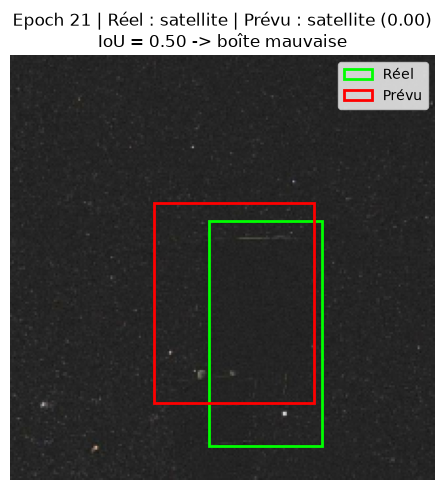

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - bbox_output_box_accuracy: 0.8266 - bbox_output_iou: 0.6360 - bbox_output_loss: 0.0018 - bbox_output_mae: 0.0451 - class_output_accuracy: 1.0000 - class_output_loss: 1.9480e-04 - loss: 0.0092 - val_bbox_output_box_accuracy: 0.7029 - val_bbox_output_iou: 0.5647 - val_bbox_output_loss: 0.0031 - val_bbox_output_mae: 0.0584 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0380 - val_loss: 0.0536
Epoch 22/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8341 - bbox_output_iou: 0.6377 - bbox_output_loss: 0.0018 - bbox_output_mae: 0.0447 - class_output_accuracy: 1.0000 - class_output_loss: 1.4643e-04 - loss: 0.0090

2026-11-25 10:39:55 [INFO] : root : Epoch 22 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.71 -> boîte bonne


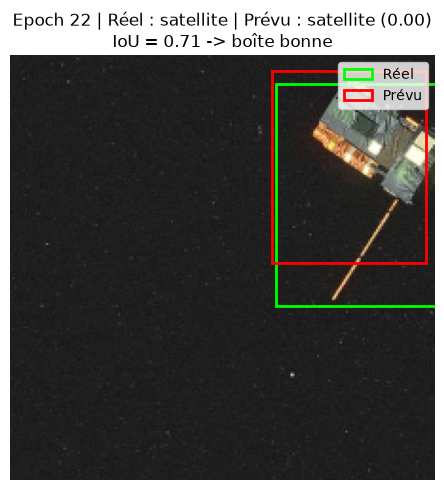

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - bbox_output_box_accuracy: 0.8342 - bbox_output_iou: 0.6379 - bbox_output_loss: 0.0018 - bbox_output_mae: 0.0447 - class_output_accuracy: 1.0000 - class_output_loss: 1.4510e-04 - loss: 0.0090 - val_bbox_output_box_accuracy: 0.6904 - val_bbox_output_iou: 0.5492 - val_bbox_output_loss: 0.0032 - val_bbox_output_mae: 0.0604 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0361 - val_loss: 0.0525
Epoch 23/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8513 - bbox_output_iou: 0.6522 - bbox_output_loss: 0.0016 - bbox_output_mae: 0.0423 - class_output_accuracy: 1.0000 - class_output_loss: 1.3649e-04 - loss: 0.0081

2026-11-25 10:39:58 [INFO] : root : Epoch 23 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.46 -> boîte mauvaise


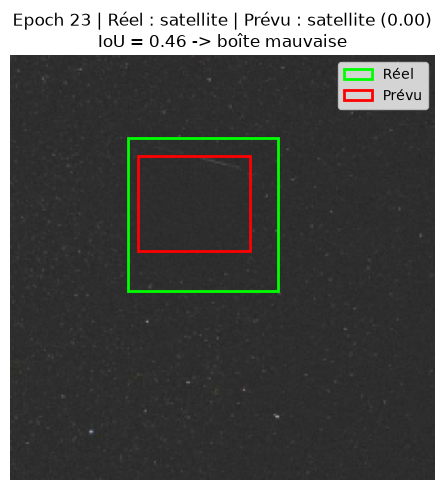

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.8532 - bbox_output_iou: 0.6527 - bbox_output_loss: 0.0016 - bbox_output_mae: 0.0423 - class_output_accuracy: 1.0000 - class_output_loss: 1.3514e-04 - loss: 0.0080 - val_bbox_output_box_accuracy: 0.7029 - val_bbox_output_iou: 0.5548 - val_bbox_output_loss: 0.0028 - val_bbox_output_mae: 0.0564 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0351 - val_loss: 0.0493
Epoch 24/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8423 - bbox_output_iou: 0.6479 - bbox_output_loss: 0.0017 - bbox_output_mae: 0.0429 - class_output_accuracy: 1.0000 - class_output_loss: 1.6957e-04 - loss: 0.0084

2026-11-25 10:40:01 [INFO] : root : Epoch 24 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.33 -> boîte mauvaise


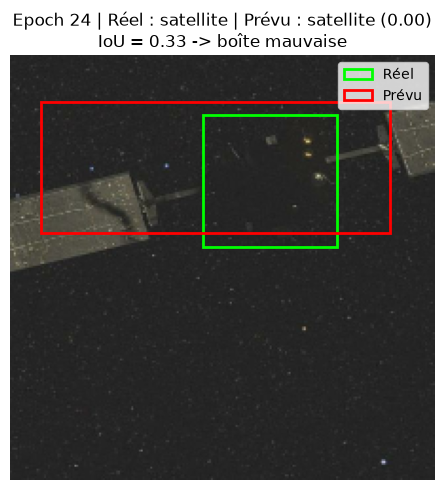

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - bbox_output_box_accuracy: 0.8423 - bbox_output_iou: 0.6479 - bbox_output_loss: 0.0017 - bbox_output_mae: 0.0429 - class_output_accuracy: 1.0000 - class_output_loss: 1.6957e-04 - loss: 0.0084 - val_bbox_output_box_accuracy: 0.7113 - val_bbox_output_iou: 0.5777 - val_bbox_output_loss: 0.0025 - val_bbox_output_mae: 0.0530 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0352 - val_loss: 0.0480
Epoch 25/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - bbox_output_box_accuracy: 0.8537 - bbox_output_iou: 0.6523 - bbox_output_loss: 0.0016 - bbox_output_mae: 0.0421 - class_output_accuracy: 1.0000 - class_output_loss: 3.1250e-04 - loss: 0.0081

2026-11-25 10:40:04 [INFO] : root : Epoch 25 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.72 -> boîte bonne


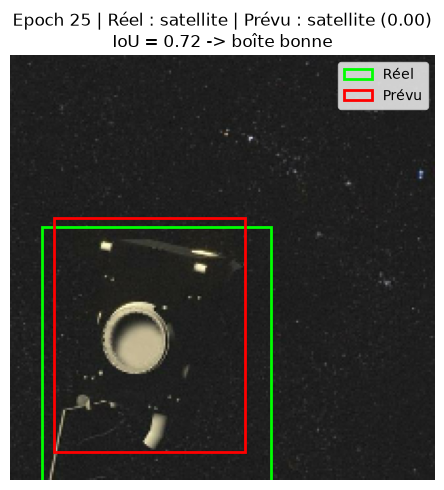

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - bbox_output_box_accuracy: 0.8532 - bbox_output_iou: 0.6518 - bbox_output_loss: 0.0016 - bbox_output_mae: 0.0421 - class_output_accuracy: 1.0000 - class_output_loss: 3.0853e-04 - loss: 0.0081 - val_bbox_output_box_accuracy: 0.7406 - val_bbox_output_iou: 0.5849 - val_bbox_output_loss: 0.0026 - val_bbox_output_mae: 0.0524 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0349 - val_loss: 0.0478
Epoch 26/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.8616 - bbox_output_iou: 0.6639 - bbox_output_loss: 0.0014 - bbox_output_mae: 0.0402 - class_output_accuracy: 1.0000 - class_output_loss: 9.0937e-05 - loss: 0.0072

2026-11-25 10:40:06 [INFO] : root : Epoch 26 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.28 -> boîte mauvaise


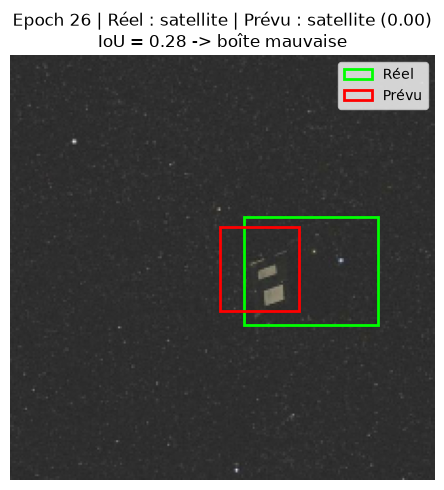

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - bbox_output_box_accuracy: 0.8622 - bbox_output_iou: 0.6642 - bbox_output_loss: 0.0014 - bbox_output_mae: 0.0401 - class_output_accuracy: 1.0000 - class_output_loss: 9.0565e-05 - loss: 0.0071 - val_bbox_output_box_accuracy: 0.7322 - val_bbox_output_iou: 0.5845 - val_bbox_output_loss: 0.0026 - val_bbox_output_mae: 0.0527 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0321 - val_loss: 0.0454
Epoch 27/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8697 - bbox_output_iou: 0.6705 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0389 - class_output_accuracy: 1.0000 - class_output_loss: 8.4815e-05 - loss: 0.0067

2026-11-25 10:40:09 [INFO] : root : Epoch 27 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.49 -> boîte mauvaise


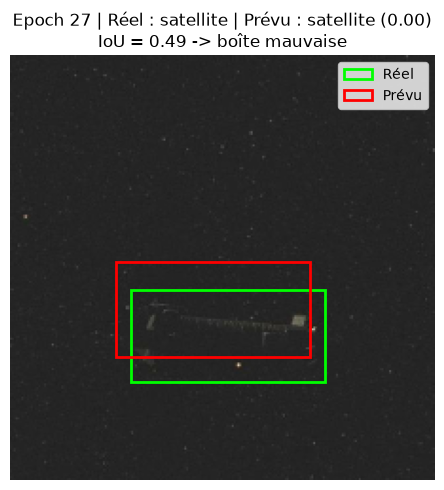

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.8703 - bbox_output_iou: 0.6707 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0390 - class_output_accuracy: 1.0000 - class_output_loss: 8.4416e-05 - loss: 0.0067 - val_bbox_output_box_accuracy: 0.6402 - val_bbox_output_iou: 0.5429 - val_bbox_output_loss: 0.0031 - val_bbox_output_mae: 0.0571 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0311 - val_loss: 0.0467
Epoch 28/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8817 - bbox_output_iou: 0.6743 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0383 - class_output_accuracy: 1.0000 - class_output_loss: 8.7750e-05 - loss: 0.0064

2026-11-25 10:40:11 [INFO] : root : Epoch 28 - Réel : debris | Prévu : debris (p_debris=1.00) | IoU=0.71 -> boîte bonne


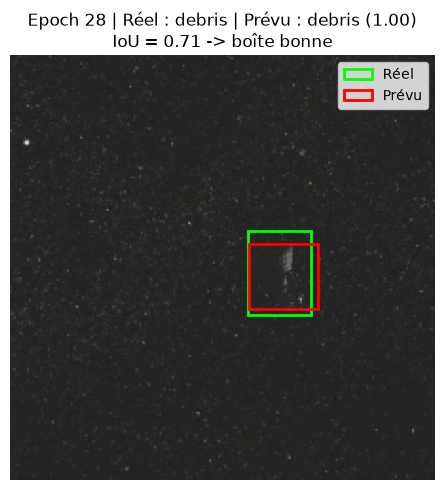

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.8822 - bbox_output_iou: 0.6744 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0383 - class_output_accuracy: 1.0000 - class_output_loss: 8.7642e-05 - loss: 0.0064 - val_bbox_output_box_accuracy: 0.7406 - val_bbox_output_iou: 0.5940 - val_bbox_output_loss: 0.0026 - val_bbox_output_mae: 0.0513 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0321 - val_loss: 0.0451
Epoch 29/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - bbox_output_box_accuracy: 0.6937 - bbox_output_iou: 0.5612 - bbox_output_loss: 0.0036 - bbox_output_mae: 0.0622 - class_output_accuracy: 0.9967 - class_output_loss: 0.0120 - loss: 0.0300

2026-11-25 10:40:14 [INFO] : root : Epoch 29 - Réel : satellite | Prévu : satellite (p_debris=0.35) | IoU=0.07 -> boîte mauvaise


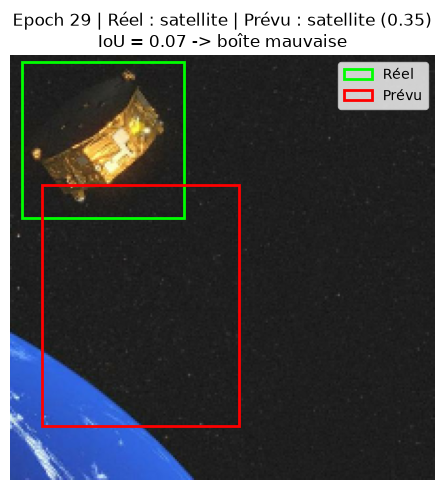

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.6931 - bbox_output_iou: 0.5611 - bbox_output_loss: 0.0036 - bbox_output_mae: 0.0622 - class_output_accuracy: 0.9967 - class_output_loss: 0.0119 - loss: 0.0299 - val_bbox_output_box_accuracy: 0.2594 - val_bbox_output_iou: 0.3522 - val_bbox_output_loss: 0.0162 - val_bbox_output_mae: 0.1368 - val_class_output_accuracy: 0.9247 - val_class_output_loss: 0.3085 - val_loss: 0.3889
Epoch 30/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.6962 - bbox_output_iou: 0.5589 - bbox_output_loss: 0.0034 - bbox_output_mae: 0.0610 - class_output_accuracy: 0.9961 - class_output_loss: 0.0223 - loss: 0.0394

2026-11-25 10:40:17 [INFO] : root : Epoch 30 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.16 -> boîte mauvaise


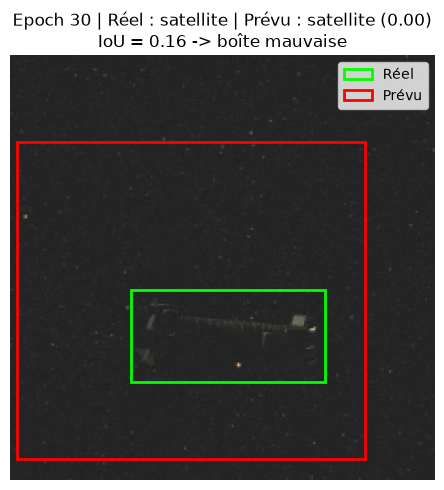

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.6903 - bbox_output_iou: 0.5566 - bbox_output_loss: 0.0035 - bbox_output_mae: 0.0615 - class_output_accuracy: 0.9957 - class_output_loss: 0.0234 - loss: 0.0408 - val_bbox_output_box_accuracy: 0.0921 - val_bbox_output_iou: 0.2495 - val_bbox_output_loss: 0.0345 - val_bbox_output_mae: 0.2149 - val_class_output_accuracy: 0.9749 - val_class_output_loss: 0.2190 - val_loss: 0.3926
Epoch 31/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.6875 - bbox_output_iou: 0.5553 - bbox_output_loss: 0.0035 - bbox_output_mae: 0.0624 - class_output_accuracy: 0.9986 - class_output_loss: 0.0103 - loss: 0.0280

2026-11-25 10:40:19 [INFO] : root : Epoch 31 - Réel : debris | Prévu : satellite (p_debris=0.00) | IoU=0.11 -> boîte mauvaise


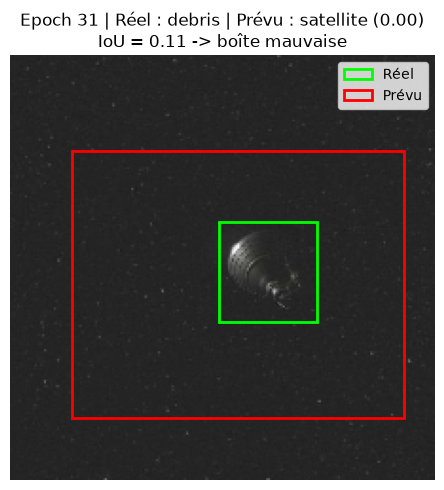

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - bbox_output_box_accuracy: 0.6888 - bbox_output_iou: 0.5558 - bbox_output_loss: 0.0035 - bbox_output_mae: 0.0623 - class_output_accuracy: 0.9986 - class_output_loss: 0.0102 - loss: 0.0278 - val_bbox_output_box_accuracy: 0.1213 - val_bbox_output_iou: 0.2757 - val_bbox_output_loss: 0.0287 - val_bbox_output_mae: 0.1887 - val_class_output_accuracy: 0.9540 - val_class_output_loss: 0.4440 - val_loss: 0.5895
Epoch 32/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.7567 - bbox_output_iou: 0.5952 - bbox_output_loss: 0.0026 - bbox_output_mae: 0.0530 - class_output_accuracy: 1.0000 - class_output_loss: 5.9053e-04 - loss: 0.0134

2026-11-25 10:40:22 [INFO] : root : Epoch 32 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.47 -> boîte mauvaise


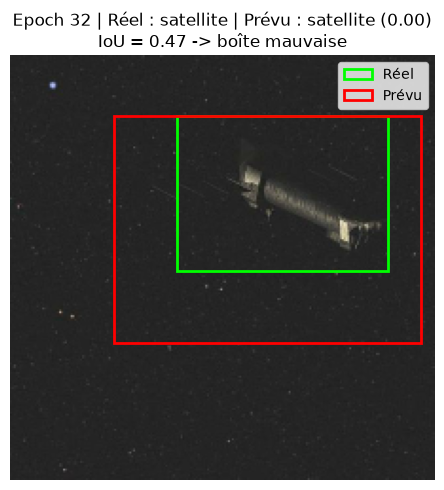

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.7558 - bbox_output_iou: 0.5949 - bbox_output_loss: 0.0026 - bbox_output_mae: 0.0530 - class_output_accuracy: 1.0000 - class_output_loss: 5.8229e-04 - loss: 0.0134 - val_bbox_output_box_accuracy: 0.1590 - val_bbox_output_iou: 0.3161 - val_bbox_output_loss: 0.0219 - val_bbox_output_mae: 0.1609 - val_class_output_accuracy: 0.9749 - val_class_output_loss: 0.2401 - val_loss: 0.3508
Epoch 33/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - bbox_output_box_accuracy: 0.7844 - bbox_output_iou: 0.6085 - bbox_output_loss: 0.0022 - bbox_output_mae: 0.0503 - class_output_accuracy: 1.0000 - class_output_loss: 2.9557e-04 - loss: 0.0115

2026-11-25 10:40:24 [INFO] : root : Epoch 33 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.43 -> boîte mauvaise


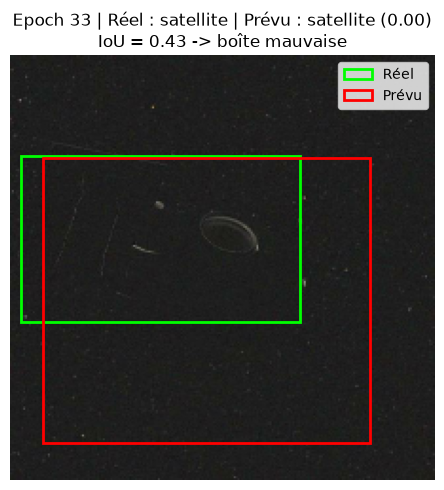

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.7848 - bbox_output_iou: 0.6086 - bbox_output_loss: 0.0022 - bbox_output_mae: 0.0503 - class_output_accuracy: 1.0000 - class_output_loss: 2.9095e-04 - loss: 0.0114 - val_bbox_output_box_accuracy: 0.2259 - val_bbox_output_iou: 0.3528 - val_bbox_output_loss: 0.0151 - val_bbox_output_mae: 0.1345 - val_class_output_accuracy: 0.9833 - val_class_output_loss: 0.1642 - val_loss: 0.2403
Epoch 34/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.7990 - bbox_output_iou: 0.6252 - bbox_output_loss: 0.0020 - bbox_output_mae: 0.0472 - class_output_accuracy: 1.0000 - class_output_loss: 4.1612e-04 - loss: 0.0105

2026-11-25 10:40:27 [INFO] : root : Epoch 34 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.38 -> boîte mauvaise


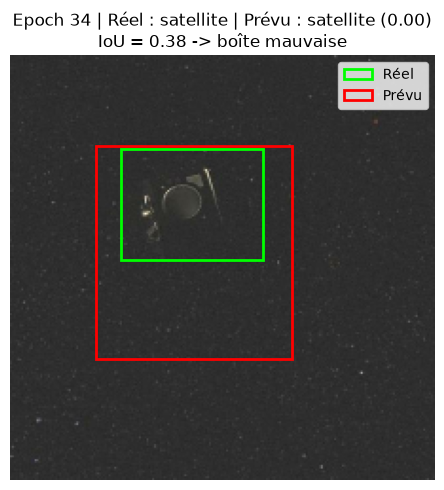

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - bbox_output_box_accuracy: 0.7995 - bbox_output_iou: 0.6256 - bbox_output_loss: 0.0020 - bbox_output_mae: 0.0472 - class_output_accuracy: 1.0000 - class_output_loss: 4.1046e-04 - loss: 0.0104 - val_bbox_output_box_accuracy: 0.3598 - val_bbox_output_iou: 0.4183 - val_bbox_output_loss: 0.0096 - val_bbox_output_mae: 0.1078 - val_class_output_accuracy: 0.9874 - val_class_output_loss: 0.1045 - val_loss: 0.1531
Epoch 35/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8133 - bbox_output_iou: 0.6315 - bbox_output_loss: 0.0019 - bbox_output_mae: 0.0459 - class_output_accuracy: 1.0000 - class_output_loss: 1.9601e-04 - loss: 0.0097

2026-11-25 10:40:29 [INFO] : root : Epoch 35 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.86 -> boîte bonne


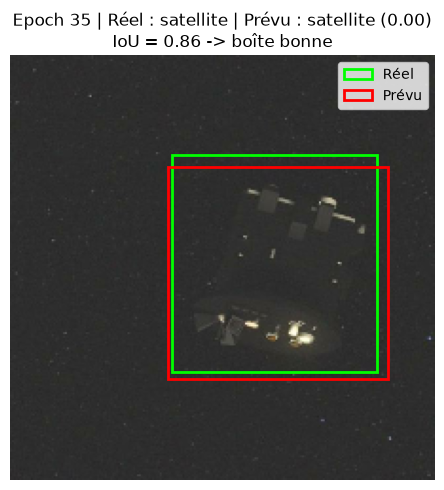

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - bbox_output_box_accuracy: 0.8133 - bbox_output_iou: 0.6315 - bbox_output_loss: 0.0019 - bbox_output_mae: 0.0459 - class_output_accuracy: 1.0000 - class_output_loss: 1.9601e-04 - loss: 0.0097 - val_bbox_output_box_accuracy: 0.5230 - val_bbox_output_iou: 0.5056 - val_bbox_output_loss: 0.0052 - val_bbox_output_mae: 0.0775 - val_class_output_accuracy: 0.9874 - val_class_output_loss: 0.1008 - val_loss: 0.1269
Epoch 36/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.8337 - bbox_output_iou: 0.6445 - bbox_output_loss: 0.0017 - bbox_output_mae: 0.0437 - class_output_accuracy: 1.0000 - class_output_loss: 1.8804e-04 - loss: 0.0089

2026-11-25 10:40:32 [INFO] : root : Epoch 36 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.08 -> boîte mauvaise


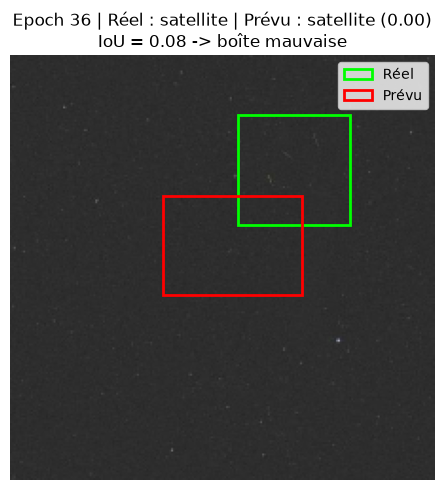

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.8347 - bbox_output_iou: 0.6448 - bbox_output_loss: 0.0017 - bbox_output_mae: 0.0437 - class_output_accuracy: 1.0000 - class_output_loss: 1.8741e-04 - loss: 0.0088 - val_bbox_output_box_accuracy: 0.5774 - val_bbox_output_iou: 0.5273 - val_bbox_output_loss: 0.0043 - val_bbox_output_mae: 0.0706 - val_class_output_accuracy: 0.9874 - val_class_output_loss: 0.0931 - val_loss: 0.1151
Epoch 37/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.8270 - bbox_output_iou: 0.6438 - bbox_output_loss: 0.0017 - bbox_output_mae: 0.0439 - class_output_accuracy: 0.9995 - class_output_loss: 0.0037 - loss: 0.0123    

2026-11-25 10:40:35 [INFO] : root : Epoch 37 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.71 -> boîte bonne


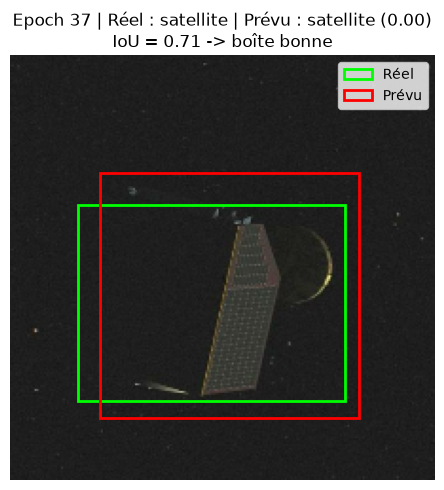

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.8257 - bbox_output_iou: 0.6426 - bbox_output_loss: 0.0018 - bbox_output_mae: 0.0442 - class_output_accuracy: 0.9995 - class_output_loss: 0.0036 - loss: 0.0124 - val_bbox_output_box_accuracy: 0.5314 - val_bbox_output_iou: 0.5054 - val_bbox_output_loss: 0.0054 - val_bbox_output_mae: 0.0789 - val_class_output_accuracy: 0.9916 - val_class_output_loss: 0.0663 - val_loss: 0.0934
Epoch 38/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8043 - bbox_output_iou: 0.6236 - bbox_output_loss: 0.0021 - bbox_output_mae: 0.0476 - class_output_accuracy: 0.9995 - class_output_loss: 0.0020 - loss: 0.0123

2026-11-25 10:40:37 [INFO] : root : Epoch 38 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.20 -> boîte mauvaise


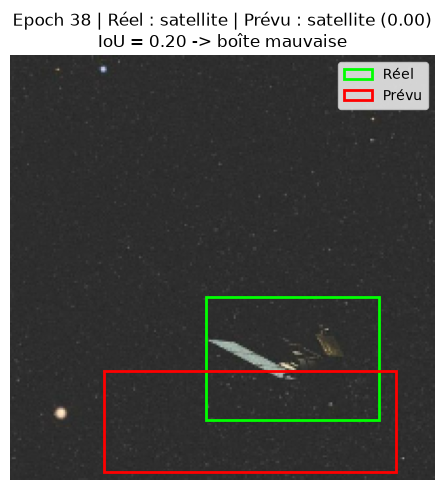

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.8033 - bbox_output_iou: 0.6227 - bbox_output_loss: 0.0021 - bbox_output_mae: 0.0478 - class_output_accuracy: 0.9995 - class_output_loss: 0.0020 - loss: 0.0124 - val_bbox_output_box_accuracy: 0.4393 - val_bbox_output_iou: 0.4592 - val_bbox_output_loss: 0.0077 - val_bbox_output_mae: 0.0941 - val_class_output_accuracy: 0.9289 - val_class_output_loss: 0.6104 - val_loss: 0.6515
Epoch 39/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8333 - bbox_output_iou: 0.6426 - bbox_output_loss: 0.0017 - bbox_output_mae: 0.0442 - class_output_accuracy: 1.0000 - class_output_loss: 3.6244e-04 - loss: 0.0091

2026-11-25 10:40:40 [INFO] : root : Epoch 39 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.84 -> boîte bonne


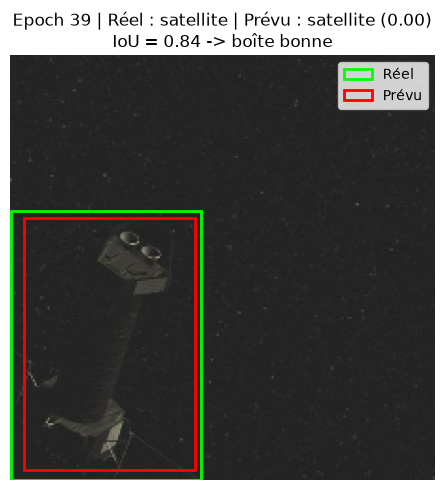

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.8337 - bbox_output_iou: 0.6432 - bbox_output_loss: 0.0017 - bbox_output_mae: 0.0441 - class_output_accuracy: 1.0000 - class_output_loss: 3.5546e-04 - loss: 0.0090 - val_bbox_output_box_accuracy: 0.6360 - val_bbox_output_iou: 0.5493 - val_bbox_output_loss: 0.0039 - val_bbox_output_mae: 0.0661 - val_class_output_accuracy: 0.9749 - val_class_output_loss: 0.1362 - val_loss: 0.1565
Epoch 40/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8368 - bbox_output_iou: 0.6506 - bbox_output_loss: 0.0016 - bbox_output_mae: 0.0427 - class_output_accuracy: 0.9995 - class_output_loss: 5.7208e-04 - loss: 0.0088

2026-11-25 10:40:42 [INFO] : root : Epoch 40 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.81 -> boîte bonne


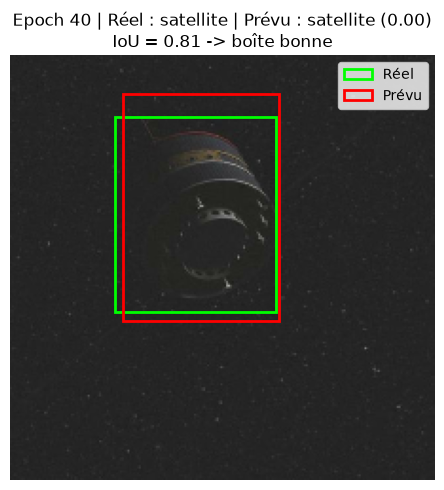

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.8361 - bbox_output_iou: 0.6502 - bbox_output_loss: 0.0016 - bbox_output_mae: 0.0427 - class_output_accuracy: 0.9995 - class_output_loss: 5.7536e-04 - loss: 0.0088 - val_bbox_output_box_accuracy: 0.6987 - val_bbox_output_iou: 0.5791 - val_bbox_output_loss: 0.0032 - val_bbox_output_mae: 0.0587 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0177 - val_loss: 0.0335
Epoch 41/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.8382 - bbox_output_iou: 0.6506 - bbox_output_loss: 0.0016 - bbox_output_mae: 0.0427 - class_output_accuracy: 1.0000 - class_output_loss: 3.5086e-04 - loss: 0.0085

2026-11-25 10:40:45 [INFO] : root : Epoch 41 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.83 -> boîte bonne


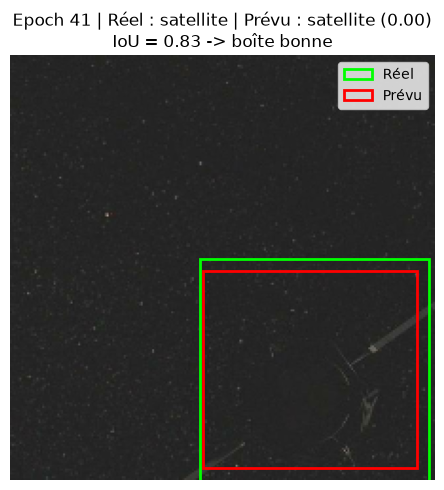

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.8394 - bbox_output_iou: 0.6505 - bbox_output_loss: 0.0016 - bbox_output_mae: 0.0427 - class_output_accuracy: 1.0000 - class_output_loss: 3.4430e-04 - loss: 0.0084 - val_bbox_output_box_accuracy: 0.7531 - val_bbox_output_iou: 0.6068 - val_bbox_output_loss: 0.0025 - val_bbox_output_mae: 0.0519 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0332 - val_loss: 0.0459
Epoch 42/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8466 - bbox_output_iou: 0.6564 - bbox_output_loss: 0.0015 - bbox_output_mae: 0.0414 - class_output_accuracy: 1.0000 - class_output_loss: 1.0887e-04 - loss: 0.0077

2026-11-25 10:40:48 [INFO] : root : Epoch 42 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.56 -> boîte bonne


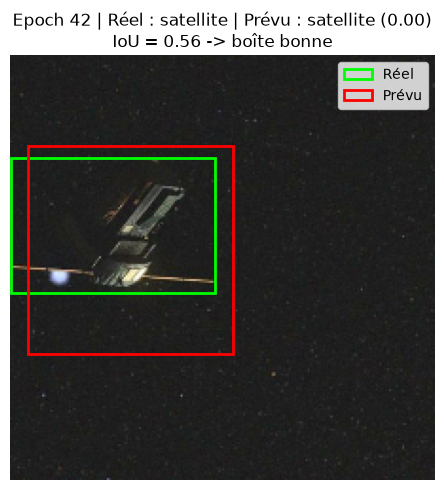

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.8475 - bbox_output_iou: 0.6567 - bbox_output_loss: 0.0015 - bbox_output_mae: 0.0414 - class_output_accuracy: 1.0000 - class_output_loss: 1.0797e-04 - loss: 0.0077 - val_bbox_output_box_accuracy: 0.7824 - val_bbox_output_iou: 0.6183 - val_bbox_output_loss: 0.0024 - val_bbox_output_mae: 0.0492 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0146 - val_loss: 0.0266
Epoch 43/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8679 - bbox_output_iou: 0.6699 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0392 - class_output_accuracy: 1.0000 - class_output_loss: 1.1555e-04 - loss: 0.0068

2026-11-25 10:40:51 [INFO] : root : Epoch 43 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.76 -> boîte bonne


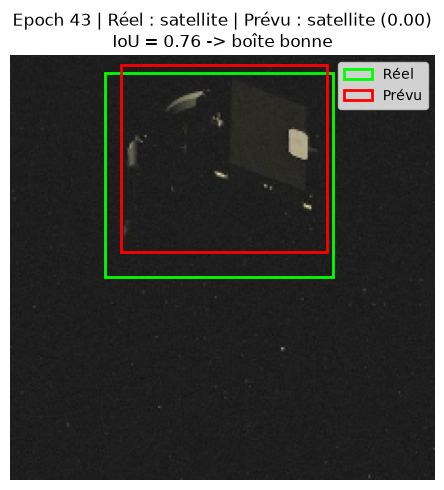

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.8679 - bbox_output_iou: 0.6699 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0392 - class_output_accuracy: 1.0000 - class_output_loss: 1.1555e-04 - loss: 0.0068 - val_bbox_output_box_accuracy: 0.7950 - val_bbox_output_iou: 0.6253 - val_bbox_output_loss: 0.0023 - val_bbox_output_mae: 0.0478 - val_class_output_accuracy: 0.9958 - val_class_output_loss: 0.0040 - val_loss: 0.0157
Epoch 44/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.8707 - bbox_output_iou: 0.6726 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0388 - class_output_accuracy: 1.0000 - class_output_loss: 7.5164e-05 - loss: 0.0067

2026-11-25 10:40:54 [INFO] : root : Epoch 44 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.71 -> boîte bonne


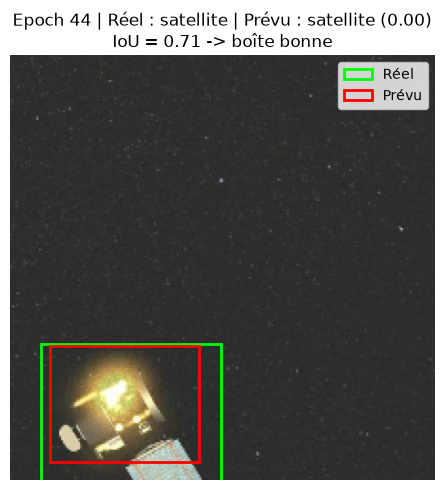

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - bbox_output_box_accuracy: 0.8713 - bbox_output_iou: 0.6726 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0388 - class_output_accuracy: 1.0000 - class_output_loss: 7.4918e-05 - loss: 0.0067 - val_bbox_output_box_accuracy: 0.7866 - val_bbox_output_iou: 0.6288 - val_bbox_output_loss: 0.0023 - val_bbox_output_mae: 0.0469 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 0.0017 - val_loss: 0.0131
Epoch 45/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8679 - bbox_output_iou: 0.6760 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0382 - class_output_accuracy: 1.0000 - class_output_loss: 1.0426e-04 - loss: 0.0066

2026-11-25 10:40:56 [INFO] : root : Epoch 45 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.48 -> boîte mauvaise


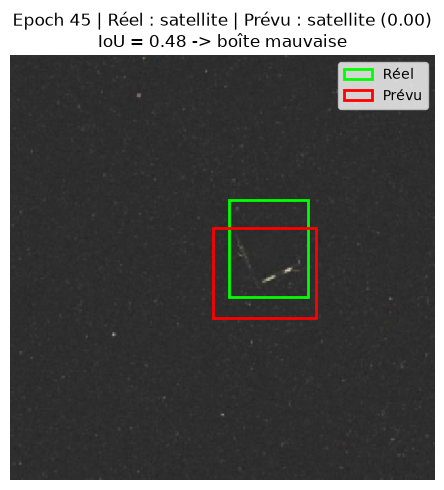

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.8679 - bbox_output_iou: 0.6760 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0382 - class_output_accuracy: 1.0000 - class_output_loss: 1.0426e-04 - loss: 0.0066 - val_bbox_output_box_accuracy: 0.7824 - val_bbox_output_iou: 0.6393 - val_bbox_output_loss: 0.0022 - val_bbox_output_mae: 0.0460 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 9.6763e-04 - val_loss: 0.0121
Epoch 46/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8629 - bbox_output_iou: 0.6767 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0382 - class_output_accuracy: 1.0000 - class_output_loss: 8.5089e-05 - loss: 0.0066

2026-11-25 10:40:59 [INFO] : root : Epoch 46 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.30 -> boîte mauvaise


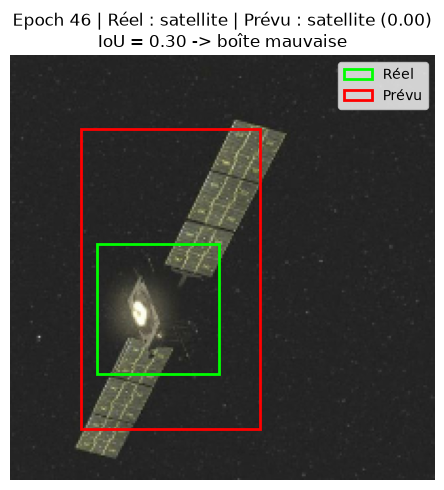

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - bbox_output_box_accuracy: 0.8637 - bbox_output_iou: 0.6769 - bbox_output_loss: 0.0013 - bbox_output_mae: 0.0381 - class_output_accuracy: 1.0000 - class_output_loss: 8.4602e-05 - loss: 0.0066 - val_bbox_output_box_accuracy: 0.7615 - val_bbox_output_iou: 0.6270 - val_bbox_output_loss: 0.0023 - val_bbox_output_mae: 0.0471 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 6.0584e-04 - val_loss: 0.0122
Epoch 47/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.8832 - bbox_output_iou: 0.6829 - bbox_output_loss: 0.0012 - bbox_output_mae: 0.0372 - class_output_accuracy: 1.0000 - class_output_loss: 6.2158e-05 - loss: 0.0060

2026-11-25 10:41:01 [INFO] : root : Epoch 47 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.82 -> boîte bonne


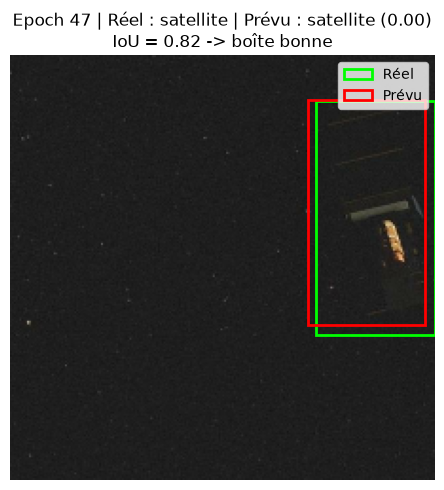

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.8831 - bbox_output_iou: 0.6826 - bbox_output_loss: 0.0012 - bbox_output_mae: 0.0372 - class_output_accuracy: 1.0000 - class_output_loss: 6.1561e-05 - loss: 0.0061 - val_bbox_output_box_accuracy: 0.8117 - val_bbox_output_iou: 0.6414 - val_bbox_output_loss: 0.0022 - val_bbox_output_mae: 0.0453 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 5.6725e-04 - val_loss: 0.0114
Epoch 48/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - bbox_output_box_accuracy: 0.8874 - bbox_output_iou: 0.6838 - bbox_output_loss: 0.0012 - bbox_output_mae: 0.0370 - class_output_accuracy: 1.0000 - class_output_loss: 9.5219e-05 - loss: 0.0061

2026-11-25 10:41:04 [INFO] : root : Epoch 48 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.39 -> boîte mauvaise


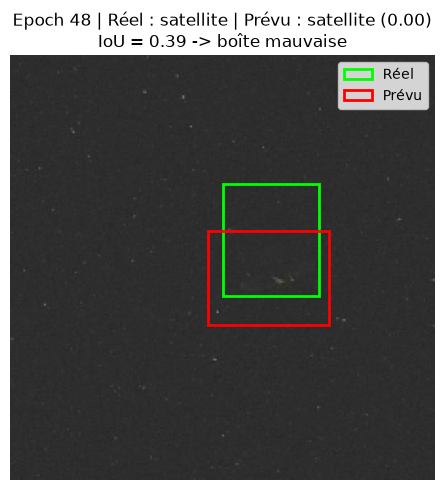

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.8879 - bbox_output_iou: 0.6839 - bbox_output_loss: 0.0012 - bbox_output_mae: 0.0370 - class_output_accuracy: 1.0000 - class_output_loss: 9.4650e-05 - loss: 0.0061 - val_bbox_output_box_accuracy: 0.7782 - val_bbox_output_iou: 0.6314 - val_bbox_output_loss: 0.0022 - val_bbox_output_mae: 0.0465 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 5.2112e-04 - val_loss: 0.0117
Epoch 49/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8871 - bbox_output_iou: 0.6853 - bbox_output_loss: 0.0012 - bbox_output_mae: 0.0368 - class_output_accuracy: 1.0000 - class_output_loss: 7.7778e-05 - loss: 0.0059

2026-11-25 10:41:07 [INFO] : root : Epoch 49 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.76 -> boîte bonne


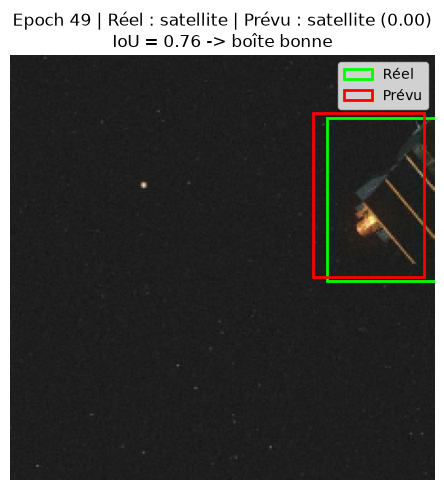

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.8855 - bbox_output_iou: 0.6845 - bbox_output_loss: 0.0012 - bbox_output_mae: 0.0368 - class_output_accuracy: 1.0000 - class_output_loss: 7.6899e-05 - loss: 0.0059 - val_bbox_output_box_accuracy: 0.7866 - val_bbox_output_iou: 0.6308 - val_bbox_output_loss: 0.0022 - val_bbox_output_mae: 0.0465 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 5.5760e-04 - val_loss: 0.0117
Epoch 50/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8841 - bbox_output_iou: 0.6889 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0361 - class_output_accuracy: 1.0000 - class_output_loss: 8.1037e-05 - loss: 0.0058

2026-11-25 10:41:09 [INFO] : root : Epoch 50 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.58 -> boîte bonne


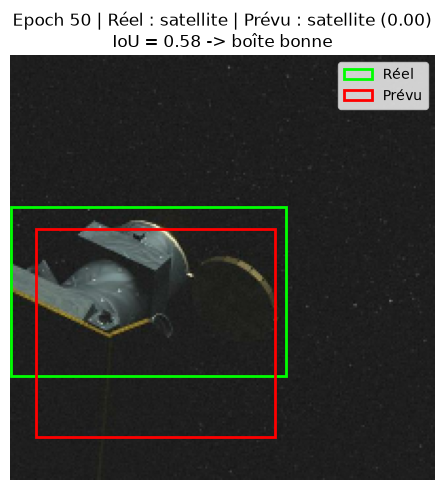

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - bbox_output_box_accuracy: 0.8841 - bbox_output_iou: 0.6889 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0361 - class_output_accuracy: 1.0000 - class_output_loss: 8.1037e-05 - loss: 0.0058 - val_bbox_output_box_accuracy: 0.7699 - val_bbox_output_iou: 0.6219 - val_bbox_output_loss: 0.0023 - val_bbox_output_mae: 0.0474 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 6.7625e-04 - val_loss: 0.0122
Epoch 51/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8950 - bbox_output_iou: 0.6913 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0358 - class_output_accuracy: 1.0000 - class_output_loss: 1.1751e-04 - loss: 0.0056

2026-11-25 10:41:12 [INFO] : root : Epoch 51 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.71 -> boîte bonne


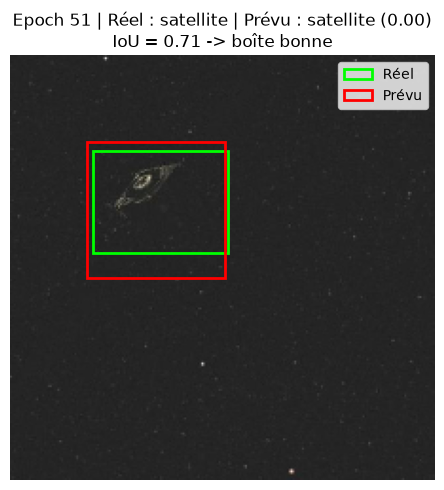

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.8950 - bbox_output_iou: 0.6913 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0358 - class_output_accuracy: 1.0000 - class_output_loss: 1.1751e-04 - loss: 0.0056 - val_bbox_output_box_accuracy: 0.7824 - val_bbox_output_iou: 0.6292 - val_bbox_output_loss: 0.0023 - val_bbox_output_mae: 0.0467 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 5.5590e-04 - val_loss: 0.0119
Epoch 52/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.8952 - bbox_output_iou: 0.6949 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0351 - class_output_accuracy: 1.0000 - class_output_loss: 8.1628e-05 - loss: 0.0055

2026-11-25 10:41:14 [INFO] : root : Epoch 52 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.70 -> boîte bonne


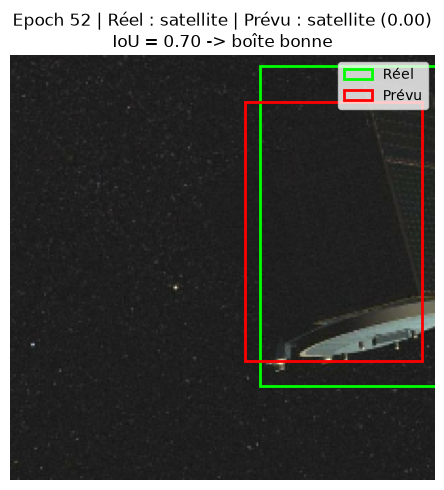

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.8950 - bbox_output_iou: 0.6945 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0352 - class_output_accuracy: 1.0000 - class_output_loss: 8.1711e-05 - loss: 0.0055 - val_bbox_output_box_accuracy: 0.7782 - val_bbox_output_iou: 0.6258 - val_bbox_output_loss: 0.0023 - val_bbox_output_mae: 0.0471 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 5.9199e-04 - val_loss: 0.0119
Epoch 53/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.8957 - bbox_output_iou: 0.6940 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0353 - class_output_accuracy: 1.0000 - class_output_loss: 6.6411e-05 - loss: 0.0055

2026-11-25 10:41:17 [INFO] : root : Epoch 53 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.50 -> boîte bonne


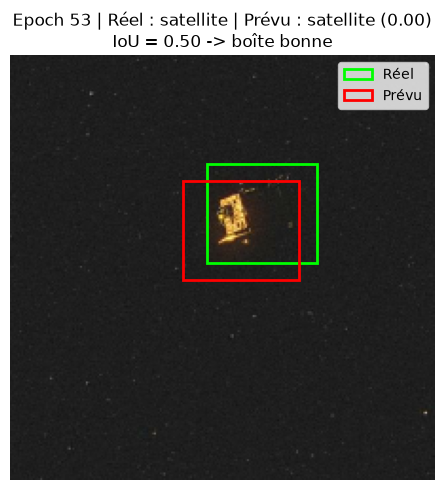

132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - bbox_output_box_accuracy: 0.8955 - bbox_output_iou: 0.6937 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0353 - class_output_accuracy: 1.0000 - class_output_loss: 6.6321e-05 - loss: 0.0055 - val_bbox_output_box_accuracy: 0.8033 - val_bbox_output_iou: 0.6330 - val_bbox_output_loss: 0.0022 - val_bbox_output_mae: 0.0461 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 6.4587e-04 - val_loss: 0.0117
Epoch 54/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.8993 - bbox_output_iou: 0.6955 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0350 - class_output_accuracy: 1.0000 - class_output_loss: 5.7582e-05 - loss: 0.0053

2026-11-25 10:41:19 [INFO] : root : Epoch 54 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.54 -> boîte bonne


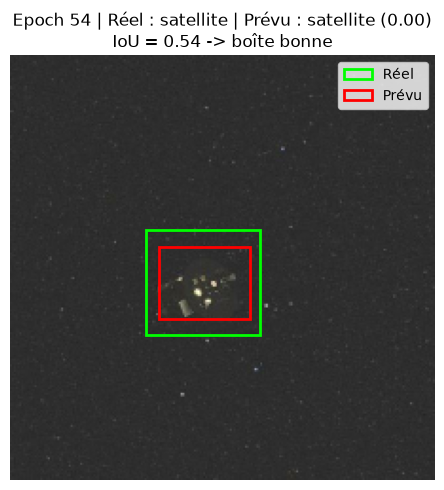

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.8993 - bbox_output_iou: 0.6955 - bbox_output_loss: 0.0011 - bbox_output_mae: 0.0350 - class_output_accuracy: 1.0000 - class_output_loss: 5.7582e-05 - loss: 0.0053 - val_bbox_output_box_accuracy: 0.7950 - val_bbox_output_iou: 0.6319 - val_bbox_output_loss: 0.0022 - val_bbox_output_mae: 0.0463 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 6.5111e-04 - val_loss: 0.0116
Epoch 55/60
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.9036 - bbox_output_iou: 0.7004 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0343 - class_output_accuracy: 1.0000 - class_output_loss: 6.6182e-05 - loss: 0.0051

2026-11-25 10:41:22 [INFO] : root : Epoch 55 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.84 -> boîte bonne


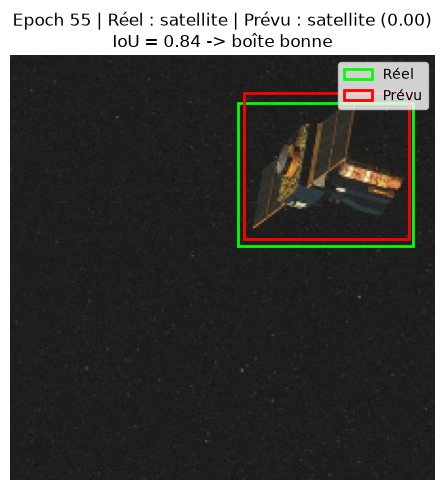

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.9036 - bbox_output_iou: 0.7002 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0344 - class_output_accuracy: 1.0000 - class_output_loss: 6.6275e-05 - loss: 0.0052 - val_bbox_output_box_accuracy: 0.8033 - val_bbox_output_iou: 0.6374 - val_bbox_output_loss: 0.0022 - val_bbox_output_mae: 0.0457 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 7.1152e-04 - val_loss: 0.0115
Epoch 56/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - bbox_output_box_accuracy: 0.9036 - bbox_output_iou: 0.6962 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0349 - class_output_accuracy: 1.0000 - class_output_loss: 1.3629e-04 - loss: 0.0054

2026-11-25 10:41:25 [INFO] : root : Epoch 56 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.71 -> boîte bonne


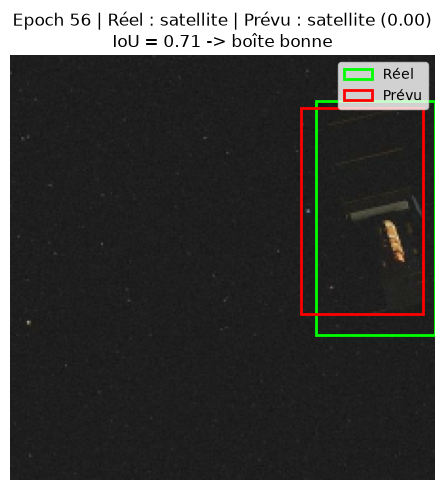

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.9031 - bbox_output_iou: 0.6958 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0349 - class_output_accuracy: 1.0000 - class_output_loss: 1.3563e-04 - loss: 0.0054 - val_bbox_output_box_accuracy: 0.8159 - val_bbox_output_iou: 0.6368 - val_bbox_output_loss: 0.0022 - val_bbox_output_mae: 0.0457 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 0.0011 - val_loss: 0.0119
Epoch 57/60
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.9077 - bbox_output_iou: 0.7018 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0342 - class_output_accuracy: 1.0000 - class_output_loss: 4.3293e-05 - loss: 0.0052

2026-11-25 10:41:27 [INFO] : root : Epoch 57 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.53 -> boîte bonne


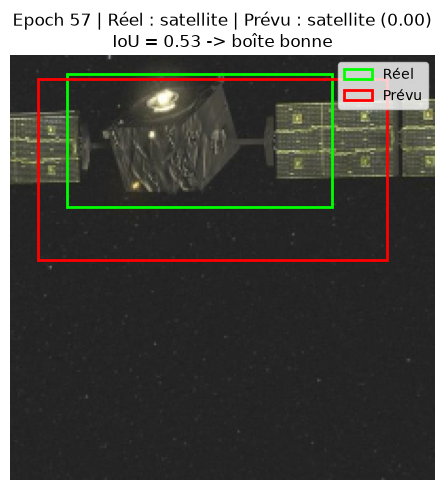

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.9074 - bbox_output_iou: 0.7017 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0342 - class_output_accuracy: 1.0000 - class_output_loss: 4.3541e-05 - loss: 0.0052 - val_bbox_output_box_accuracy: 0.8159 - val_bbox_output_iou: 0.6406 - val_bbox_output_loss: 0.0021 - val_bbox_output_mae: 0.0453 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 0.0011 - val_loss: 0.0117
Epoch 58/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.9065 - bbox_output_iou: 0.7023 - bbox_output_loss: 9.9678e-04 - bbox_output_mae: 0.0340 - class_output_accuracy: 1.0000 - class_output_loss: 5.8046e-05 - loss: 0.0050

2026-11-25 10:41:30 [INFO] : root : Epoch 58 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.55 -> boîte bonne


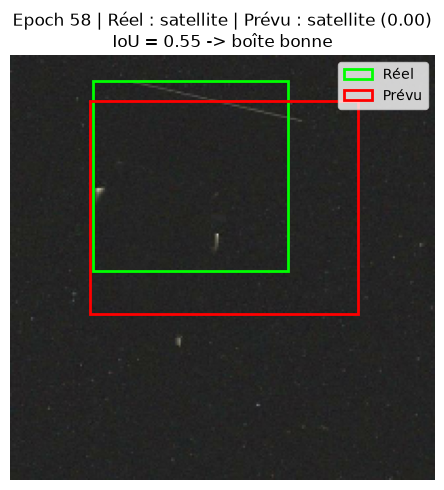

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - bbox_output_box_accuracy: 0.9069 - bbox_output_iou: 0.7026 - bbox_output_loss: 9.9683e-04 - bbox_output_mae: 0.0340 - class_output_accuracy: 1.0000 - class_output_loss: 5.7708e-05 - loss: 0.0050 - val_bbox_output_box_accuracy: 0.8117 - val_bbox_output_iou: 0.6400 - val_bbox_output_loss: 0.0021 - val_bbox_output_mae: 0.0452 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 0.0011 - val_loss: 0.0116
Epoch 59/60
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - bbox_output_box_accuracy: 0.9026 - bbox_output_iou: 0.7037 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0339 - class_output_accuracy: 1.0000 - class_output_loss: 6.2609e-05 - loss: 0.0051

2026-11-25 10:41:32 [INFO] : root : Epoch 59 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.61 -> boîte bonne


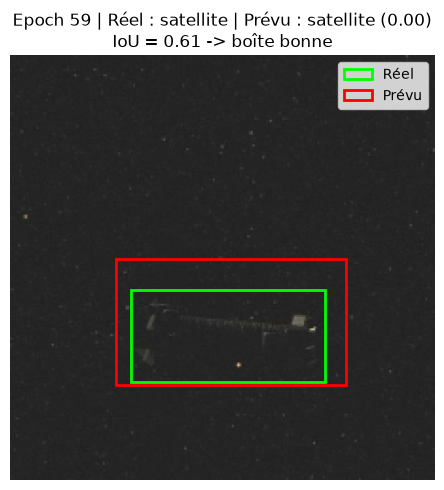

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - bbox_output_box_accuracy: 0.9026 - bbox_output_iou: 0.7037 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0339 - class_output_accuracy: 1.0000 - class_output_loss: 6.2609e-05 - loss: 0.0051 - val_bbox_output_box_accuracy: 0.8243 - val_bbox_output_iou: 0.6456 - val_bbox_output_loss: 0.0021 - val_bbox_output_mae: 0.0446 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 0.0011 - val_loss: 0.0115
Epoch 60/60
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - bbox_output_box_accuracy: 0.9022 - bbox_output_iou: 0.7016 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0341 - class_output_accuracy: 1.0000 - class_output_loss: 7.2079e-05 - loss: 0.0051

2026-11-25 10:41:35 [INFO] : root : Epoch 60 - Réel : satellite | Prévu : satellite (p_debris=0.00) | IoU=0.80 -> boîte bonne


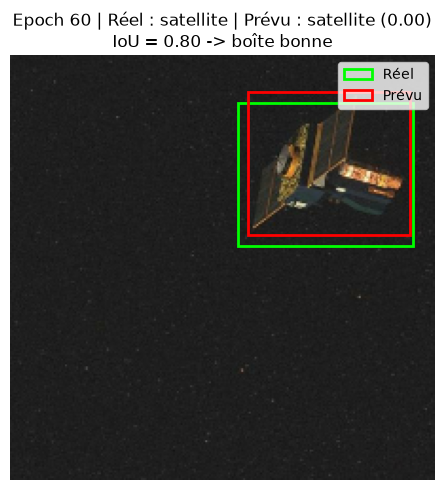

132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - bbox_output_box_accuracy: 0.9026 - bbox_output_iou: 0.7016 - bbox_output_loss: 0.0010 - bbox_output_mae: 0.0341 - class_output_accuracy: 1.0000 - class_output_loss: 7.1693e-05 - loss: 0.0051 - val_bbox_output_box_accuracy: 0.8159 - val_bbox_output_iou: 0.6486 - val_bbox_output_loss: 0.0021 - val_bbox_output_mae: 0.0442 - val_class_output_accuracy: 1.0000 - val_class_output_loss: 0.0011 - val_loss: 0.0114


In [9]:
# BLOQUE 5 - Aperçu des boîtes pendant l'entraînement
# Le callback sélectionne une image de validation par époque, prédit sa classe et sa
# boîte, puis affiche visuellement leurs relations. Il utilise 224x224 normalisé.
class EpochBBoxPreviewCallback(keras.callbacks.Callback):
    def __init__(self, dataset, class_names, threshold=0.5):
        super().__init__()
        self.class_names = class_names
        # Probabilité de debris à partir de laquelle l'objet est classé debris
        self.threshold = threshold
        self.images = []
        self.true_boxes = []
        self.true_class_ids = []

        for images, targets in dataset:
            self.images.extend(images.numpy())
            self.true_boxes.extend(targets["bbox_output"].numpy())
            self.true_class_ids.extend(targets["class_output"].numpy()[:, 0].astype(int))

    def on_epoch_end(self, epoch, logs=None):
        index = np.random.randint(len(self.images))
        image = self.images[index][np.newaxis, ...]
        true_class_name = self.class_names[self.true_class_ids[index]]

        predictions = self.model.predict(image, verbose=0)
        class_probability = float(predictions["class_output"][0, 0])
        box_iou = float(iou(self.true_boxes[index], predictions["bbox_output"][0]))
        box_verdict = "bonne" if box_iou >= IOU_THRESHOLD else "mauvaise"
        predicted_class_name = self.class_names[int(class_probability >= self.threshold)]

        logging.info(
            f"Epoch {epoch + 1} - Réel : {true_class_name} "
            f"| Prévu : {predicted_class_name} (p_debris={class_probability:.2f}) "
            f"| IoU={box_iou:.2f} -> boîte {box_verdict}"
        )

        figure, axis = plt.subplots(figsize=(5, 5))
        # MobileNetV2 attend des pixels dans [-1, 1]. Pour l'affichage,
        # reconvertit uniquement une copie vers l'intervalle RGB [0, 1].
        display_image = np.clip((image[0] + 1.0) / 2.0, 0.0, 1.0)
        height, width = display_image.shape[:2]
        axis.imshow(display_image)

        boxes = [
            (self.true_boxes[index], "lime", "Réel"),
            (predictions["bbox_output"][0], "red", "Prévu"),
        ]
        for (ymin, xmin, ymax, xmax), color, label in boxes:
            axis.add_patch(patches.Rectangle(
                (xmin * width, ymin * height),
                (xmax - xmin) * width,
                (ymax - ymin) * height,
                linewidth=2,
                edgecolor=color,
                facecolor="none",
                label=label,
            ))

        axis.set_title(
            f"Epoch {epoch + 1} | Réel : {true_class_name} "
            f"| Prévu : {predicted_class_name} ({class_probability:.2f})\n"
            f"IoU = {box_iou:.2f} -> boîte {box_verdict}"
        )
        axis.legend(loc="upper right")
        axis.axis("off")
        figure.tight_layout()
        plt.show()
        plt.close(figure)


early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_bbox_output_iou",
    mode="max",
    # Plus long que la patience de ReduceLROnPlateau pour laisser
    # le temps à un learning rate réduit d'améliorer le modèle.
    patience=220,
    restore_best_weights=True,
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        OUTPUT_PATH,
        monitor="val_bbox_output_iou",
        mode="max",
        save_best_only=True,
    ),
    early_stopping,
    EpochBBoxPreviewCallback(val_ds, CLASS_NAMES),
]

if LEARNING_RATE_MODE == "plateau":
    callbacks.append(
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_bbox_output_iou",
            mode="max",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1,
        )
    )

with tf.device(TRAINING_DEVICE):
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
    )

if early_stopping.stopped_epoch > 0:
    logging.warning(
        f"Entraînement arrêté par EarlyStopping à l'epoch {early_stopping.stopped_epoch + 1}/{EPOCHS} : "
        f"{early_stopping.monitor} ne s'est pas amélioré depuis {early_stopping.patience} epochs. "
        f"Meilleure valeur : {early_stopping.best:.4f} à l'epoch {early_stopping.best_epoch + 1}, "
        f"poids de cette epoch restaurés (et sauvegardés dans {OUTPUT_PATH})."
    )


In [10]:
# BLOQUE 6 - Évaluation finale sur test
# Le meilleur modèle selon l'IoU de validation est rechargé, recompilé et évalué sur
# les données test sans modification du checkpoint ni du seuil de détection.
best_model = keras.models.load_model(OUTPUT_PATH, compile=False)
compile_multitask_model(best_model)
test_metrics = best_model.evaluate(test_ds, return_dict=True)
logging.info("Métriques test : %s", test_metrics)

1/8 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - bbox_output_box_accuracy: 0.8750 - bbox_output_iou: 0.7021 - bbox_output_loss: 0.0021 - bbox_output_mae: 0.0512 - class_output_accuracy: 1.0000 - class_output_loss: 7.8548e-06 - loss: 0.0105

E0000 00:00:1795599700.211214  383094 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795599703.548640  383094 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - bbox_output_box_accuracy: 0.8537 - bbox_output_iou: 0.6413 - bbox_output_loss: 0.0033 - bbox_output_mae: 0.0503 - class_output_accuracy: 0.9837 - class_output_loss: 0.1790 - loss: 0.2026  


2026-11-25 10:41:47 [INFO] : root : Métriques test : {'bbox_output_box_accuracy': 0.8536585569381714, 'bbox_output_iou': 0.6413249373435974, 'bbox_output_loss': 0.0033085669856518507, 'bbox_output_mae': 0.05028778687119484, 'class_output_accuracy': 0.9837398529052734, 'class_output_loss': 0.179034024477005, 'loss': 0.20259931683540344}


## 4. Visualisation d'une prédiction

Cette cellule prend un exemple du jeu de test et affiche la boîte réelle en vert et la boîte prédite en rouge. Elle affiche aussi la probabilité de debris.

La visualisation vérifie qualitativement que les coordonnées sont correctement converties depuis `[ymin, xmin, ymax, xmax]` vers des pixels. Elle permet aussi d'identifier les décalages ou boîtes retournées.

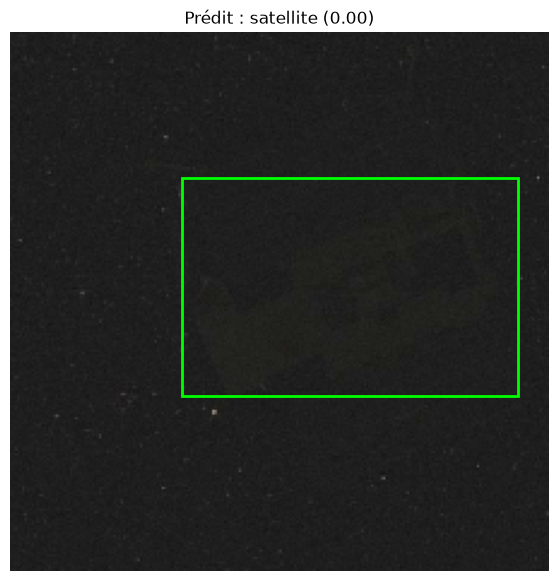

In [11]:
# BLOQUE 7 - Démonstration sur une nouvelle entrée
# Cette cellule reprend le même prétraitement qu'à l'entraînement et affiche sur une
# image test la probabilité de debris, la classe prédite et les quatre coordonnées.
images, targets = next(iter(test_ds))
predictions = best_model.predict(images, verbose=0)
index = 0
image = images[index].numpy()
image_for_display = (image + 1.0) / 2.0
class_probability = float(predictions["class_output"][index, 0])
ymin, xmin, ymax, xmax = predictions["bbox_output"][index]
height, width = image.shape[:2]

figure, axis = plt.subplots(figsize=(7, 7))
axis.imshow(np.clip(image_for_display, 0.0, 1.0))
axis.add_patch(patches.Rectangle(
    (xmin * width, ymin * height),
    (xmax - xmin) * width,
    (ymax - ymin) * height,
    linewidth=2,
    edgecolor="lime",
    facecolor="none",
))
axis.set_title(f"Prédit : {CLASS_NAMES[int(class_probability >= 0.5)]} ({class_probability:.2f})")
axis.axis("off")
plt.show()

## 5. Courbes d'apprentissage

Les graphiques suivants suivent :

- la perte totale ;
- l'IoU moyenne ;
- la MAE des coordonnées ;
- l'accuracy de classe ;
- l'accuracy des boîtes à IoU >= 0.5.

Une IoU d'entraînement supérieure à la validation avec une validation qui se dégrade indique un sur-apprentissage de la localisation.

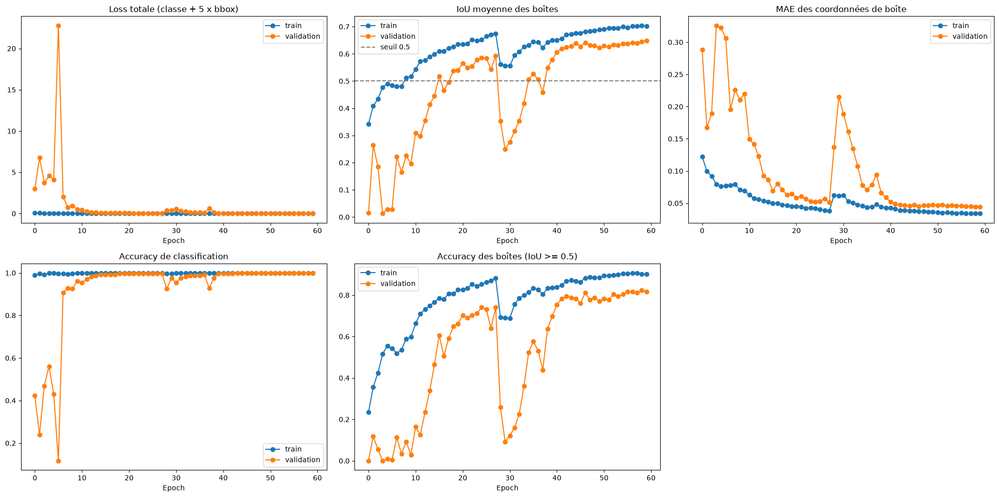

In [12]:
# BLOQUE 8 - Courbes de classe et de localisation
# Les graphiques suivent la perte totale, l'IoU, la MAE, l'accuracy de classe et
# l'accuracy des boîtes pour détecter une divergence train/validation.
metrics = history.history

figure, axes = plt.subplots(2, 3, figsize=(20, 10))

for axis, (metric_name, title) in zip(axes.flatten(), [
    ("loss", "Loss totale (classe + 5 x bbox)"),
    ("bbox_output_iou", "IoU moyenne des boîtes"),
    ("bbox_output_mae", "MAE des coordonnées de boîte"),
    ("class_output_accuracy", "Accuracy de classification"),
    ("bbox_output_box_accuracy", f"Accuracy des boîtes (IoU >= {IOU_THRESHOLD})"),
]):
    axis.plot(history.epoch, metrics[metric_name], "o-", label="train")
    axis.plot(history.epoch, metrics[f"val_{metric_name}"], "o-", label="validation")
    if metric_name == "bbox_output_iou":
        axis.axhline(IOU_THRESHOLD, color="gray", linestyle="--", label=f"seuil {IOU_THRESHOLD}")
    axis.set_title(title)
    axis.set_xlabel("Epoch")
    axis.legend()

# 5 courbes pour 6 emplacements : on masque le dernier
axes.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()


## 6. Analyse détaillée sur test

Cette partie conserve une séparation claire entre classe et géométrie :

- rapport de classification pour mesurer précision/rappel ;
- matrice de confusion pour les erreurs satellite/debris ;
- distribution des IoU pour repérer les boîtes proches ou très éloignées ;
- taux de détection complète, qui exige simultanément une bonne classe et une IoU >= 0.5.

Un système peut donc obtenir une bonne précision de classe tout en produisant des boîtes insuffisamment proches.

2026-11-25 10:41:50 [INFO] : root : Classification sur le test :
              precision    recall  f1-score   support

   satellite     0.9825    1.0000    0.9912       112
      debris     1.0000    0.8182    0.9000        11

    accuracy                         0.9837       123
   macro avg     0.9912    0.9091    0.9456       123
weighted avg     0.9840    0.9837    0.9830       123

2026-11-25 10:41:50 [INFO] : root : IoU test : moyenne=0.641, médiane=0.673
2026-11-25 10:41:50 [INFO] : root : Boîtes correctes (IoU >= 0.5) : 85.4 %
2026-11-25 10:41:50 [INFO] : root : Détections correctes (classe + boîte) : 85.4 %
2026-11-25 10:41:50 [INFO] : root :   satellite : IoU moyenne=0.669, boîtes correctes=90.2 %
2026-11-25 10:41:50 [INFO] : root :   debris : IoU moyenne=0.357, boîtes correctes=36.4 %


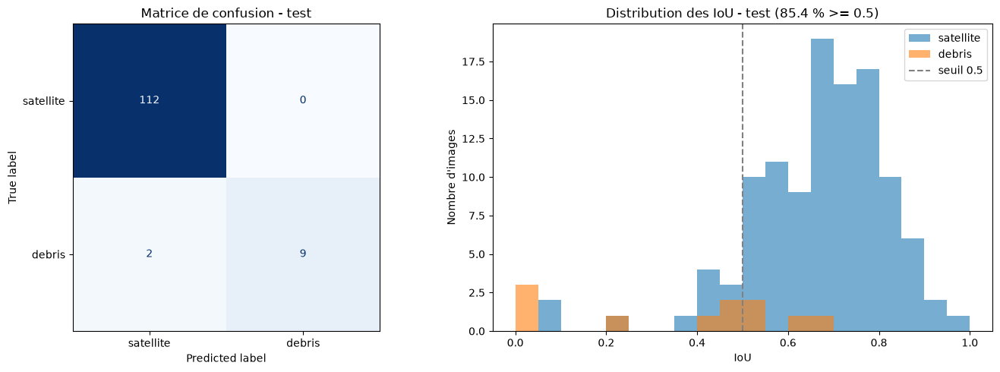

In [13]:
# BLOQUE 9 - Évaluation quantitative approfondie
# Ce bloc mesure les erreurs de classe, la distribution des IoU et le taux de cas
# satisfaisant simultanément la bonne classe et une IoU supérieure ou égale à 0.5.
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

y_test = []
true_boxes_test = []
p_test = []
pred_boxes_test = []
for images, targets in test_ds:
    predictions = best_model.predict(images, verbose=0)
    y_test.append(targets["class_output"].numpy()[:, 0].astype(int))
    true_boxes_test.append(targets["bbox_output"].numpy())
    p_test.append(predictions["class_output"][:, 0])
    pred_boxes_test.append(predictions["bbox_output"])

y_test = np.concatenate(y_test)
true_boxes_test = np.concatenate(true_boxes_test)
p_test = np.concatenate(p_test)
pred_boxes_test = np.concatenate(pred_boxes_test)

pred_test = (p_test >= 0.5).astype(int)
iou_test = keras.ops.convert_to_numpy(iou(true_boxes_test, pred_boxes_test))
good_box = iou_test >= IOU_THRESHOLD
good_detection = good_box & (pred_test == y_test)

logging.info("Classification sur le test :\n%s", classification_report(y_test, pred_test, target_names=CLASS_NAMES, digits=4))
logging.info("IoU test : moyenne=%.3f, médiane=%.3f", iou_test.mean(), np.median(iou_test))
logging.info("Boîtes correctes (IoU >= %.1f) : %.1f %%", IOU_THRESHOLD, 100 * good_box.mean())
logging.info("Détections correctes (classe + boîte) : %.1f %%", 100 * good_detection.mean())
for class_id, class_name in enumerate(CLASS_NAMES):
    mask = y_test == class_id
    if mask.any():
        logging.info("  %s : IoU moyenne=%.3f, boîtes correctes=%.1f %%",
                     class_name, iou_test[mask].mean(), 100 * good_box[mask].mean())

figure, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES).plot(cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Matrice de confusion - test")

for class_id, class_name in enumerate(CLASS_NAMES):
    axes[1].hist(iou_test[y_test == class_id], bins=20, range=(0, 1), alpha=0.6, label=class_name)
axes[1].axvline(IOU_THRESHOLD, color="gray", linestyle="--", label=f"seuil {IOU_THRESHOLD}")
axes[1].set_title(f"Distribution des IoU - test ({100 * good_box.mean():.1f} % >= {IOU_THRESHOLD})")
axes[1].set_xlabel("IoU")
axes[1].set_ylabel("Nombre d'images")
axes[1].legend()

plt.tight_layout()
plt.show()


## 7. Sauvegarde et rechargement

Le meilleur modèle est sauvegardé au format Keras dans `models/BBOX/`. Lors du chargement pour une nouvelle image, l'exécution doit conserver les fonctions personnalisées `iou` et `box_accuracy` ou les fournir comme objets personnalisés si elles sont utilisées à la compilation.

## 8. Comparaison des variantes de détection

Cette cellule charge tous les modèles du dossier `models/BBOX/` et les évalue avec les mêmes données de test. Elle produit un tableau commun pour comparer classification, IoU moyenne, MAE, taux de boîtes correctes et erreurs du pipeline complet.

Seuls les fichiers réellement réutilisables doivent être retenus dans la version finale ; les modèles temporaires ou `A_SUPPRIMER` ne constituent pas des variantes finalisées.

In [14]:
# BLOQUE 10 - Comparaison des variantes enregistrées
# Tous les checkpoints reconnus dans models/BBOX sont évalués sur test avec les mêmes
# métriques afin d'identifier le meilleur compromis entre classe et localisation.
from pathlib import Path

from sklearn.metrics import accuracy_score, average_precision_score, f1_score, precision_score, recall_score

model_paths = sorted(Path("src/models/BBOX").glob("*.keras"))
if not model_paths:
    raise FileNotFoundError("Aucun modèle .keras trouvé dans le dossier models/BBOX.")

true_classes = []
true_boxes = []
for _, targets in test_ds:
    true_classes.append(targets["class_output"].numpy()[:, 0].astype(int))
    true_boxes.append(targets["bbox_output"].numpy())
true_classes = np.concatenate(true_classes)
true_boxes = np.concatenate(true_boxes)

def compute_iou_numpy(boxes_true, boxes_pred):
    inter_ymin = np.maximum(boxes_true[:, 0], boxes_pred[:, 0])
    inter_xmin = np.maximum(boxes_true[:, 1], boxes_pred[:, 1])
    inter_ymax = np.minimum(boxes_true[:, 2], boxes_pred[:, 2])
    inter_xmax = np.minimum(boxes_true[:, 3], boxes_pred[:, 3])
    intersection = np.maximum(0.0, inter_ymax - inter_ymin) * np.maximum(0.0, inter_xmax - inter_xmin)
    true_area = np.maximum(0.0, boxes_true[:, 2] - boxes_true[:, 0]) * np.maximum(0.0, boxes_true[:, 3] - boxes_true[:, 1])
    pred_area = np.maximum(0.0, boxes_pred[:, 2] - boxes_pred[:, 0]) * np.maximum(0.0, boxes_pred[:, 3] - boxes_pred[:, 1])
    union = true_area + pred_area - intersection
    return intersection / np.maximum(union, 1e-7)

comparison_results = []
for model_path in model_paths:
    try:
        candidate_model = keras.models.load_model(model_path, compile=False)
        predictions = candidate_model.predict(test_ds, verbose=0)
        probabilities = np.asarray(predictions["class_output"])[:, 0]
        predicted_boxes = np.asarray(predictions["bbox_output"])
        predicted_classes = (probabilities >= 0.5).astype(int)
        ious = compute_iou_numpy(true_boxes, predicted_boxes)
        good_boxes = ious >= IOU_THRESHOLD
        complete_detections = good_boxes & (predicted_classes == true_classes)
        comparison_results.append({
            "modèle": model_path.name,
            "statut": "OK",
            "accuracy_classe": accuracy_score(true_classes, predicted_classes),
            "precision_debris": precision_score(true_classes, predicted_classes, zero_division=0),
            "f1_debris": f1_score(true_classes, predicted_classes, zero_division=0),
            "pr_auc_debris": average_precision_score(true_classes, probabilities),
            "iou_moyenne": ious.mean(),
            "iou_mediane": np.median(ious),
            "boites_correctes": good_boxes.mean(),
            "detections_completes": complete_detections.mean(),
        })
    except Exception as error:
        comparison_results.append({"modèle": model_path.name, "statut": f"ERREUR: {type(error).__name__}: {error}"})

bbox_comparison = pd.DataFrame(comparison_results)
display(bbox_comparison)

2026-11-25 10:41:57 [WARNING] : tensorflow : 5 out of the last 18 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x71e83bd55bc0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


2026-11-25 10:42:00 [WARNING] : tensorflow : 5 out of the last 17 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x71e83b949b20> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


,modèle,statut,accuracy_classe,precision_debris,f1_debris,pr_auc_debris,iou_moyenne,iou_mediane,boites_correctes,detections_completes
0,A_SUPPRIMER.keras,OK,0.98374,1.0,0.900000,0.870145,0.641325,0.672572,0.853659,0.853659
1,satellite_debris_bbox_cosin_decay.keras,OK,0.98374,1.0,0.900000,0.917221,0.662037,0.682809,0.853659,0.853659
2,satellite_debris_bbox_hardcoded.keras,OK,0.98374,1.0,0.900000,0.910172,0.657786,0.700122,0.861789,0.861789
3,satellite_debris_bbox_lronplateau.keras,OK,0.97561,1.0,0.842105,0.909301,0.660352,0.694500,0.878049,0.878049


## 9. IA symbolique : interprétation des prédictions

Cette partie ajoute une couche explicable aux sorties du réseau profond. Elle applique uniquement des règles vérifiables : domaine des probabilités, domaine et géométrie de la boîte, proximité du seuil de décision et taille anormalement petite d'un debris.

La couche symbolique ne corrige pas automatiquement la prédiction. Elle indique si le cas est `confiant`, `incertain` ou `sortie_invalide`, puis recommande ou non une supervision humaine.

In [15]:
# BLOQUE 11 - Règles symboliques explicables
# Le réseau reste responsable des probabilités et des coordonnées. Les règles ci-dessous
# expliquent seulement les résultats et peuvent demander une vérification humaine.

from UTILS.symbolic_rules import apply_symbolic_rules

symbolic_results = []
SYMBOLIC_DECISION_THRESHOLD = 0.5

for images, targets in test_ds:
    predictions = best_model.predict(images, verbose=0)
    probabilities = predictions["class_output"][:, 0]
    predicted_boxes = predictions["bbox_output"]

    for probability, bbox in zip(probabilities, predicted_boxes):
        symbolic_results.append(
            apply_symbolic_rules(
                probability_debris=probability,
                bbox=bbox,
                decision_threshold=SYMBOLIC_DECISION_THRESHOLD,
            )
        )

symbolic_summary = pd.DataFrame(symbolic_results)
symbolic_summary["status"].value_counts()


status
confiant     122
incertain      1
Name: count, dtype: int64

## 10. Confirmation finale du modèle de boîtes retenu

Cette section charge explicitement le candidat retenu provisoirement : `satellite_debris_bbox_lronplateau.keras`. Elle confirme les métriques de classe, d'IoU et de détection complète sur le test, puis sauvegarde les preuves dans `results/final/BBOX`.

Le modèle temporaire `A_SUPPRIMER.keras` n'est pas utilisé comme modèle final.

In [16]:
# BLOQUE 12 - Confirmation du modèle de boîtes retenu
import json
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

FINAL_BBOX_MODEL = Path("src/models/BBOX/satellite_debris_bbox_lronplateau.keras")
FINAL_RESULTS_DIR = Path("results/final/BBOX")
FINAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not FINAL_BBOX_MODEL.exists():
    raise FileNotFoundError(f"Modèle de boîtes retenu introuvable : {FINAL_BBOX_MODEL}")

final_bbox_model = keras.models.load_model(FINAL_BBOX_MODEL, compile=False)
compile_multitask_model(final_bbox_model)

y_true_class = []
y_true_boxes = []
y_pred_class = []
y_pred_boxes = []
for images, targets in test_ds:
    predictions = final_bbox_model.predict(images, verbose=0)
    y_true_class.extend(targets["class_output"].numpy()[:, 0].astype(int).tolist())
    y_true_boxes.extend(targets["bbox_output"].numpy().tolist())
    y_pred_class.extend((predictions["class_output"][:, 0] >= 0.5).astype(int).tolist())
    y_pred_boxes.extend(predictions["bbox_output"].tolist())

y_true_class = np.array(y_true_class)
y_true_boxes = np.array(y_true_boxes)
y_pred_class = np.array(y_pred_class)
y_pred_boxes = np.array(y_pred_boxes)

iou_values = np.array([
    float(iou(tf.convert_to_tensor([true_box], dtype=tf.float32), tf.convert_to_tensor([pred_box], dtype=tf.float32)).numpy()[0])
    for true_box, pred_box in zip(y_true_boxes, y_pred_boxes)
])
boites_correctes = iou_values >= IOU_THRESHOLD
detections_completes = (y_true_class == y_pred_class) & boites_correctes

cm = confusion_matrix(y_true_class, y_pred_class)
figure, axis = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", ax=axis, colorbar=False)
axis.set_title("Modèle de boîtes retenu - matrice test")
figure.tight_layout()
figure.savefig(FINAL_RESULTS_DIR / "bbox_confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.close(figure)

figure, axis = plt.subplots(figsize=(7, 5))
axis.hist(iou_values, bins=np.linspace(0, 1, 21), edgecolor="black")
axis.axvline(IOU_THRESHOLD, color="red", linestyle="--", label=f"IoU={IOU_THRESHOLD:.1f}")
axis.set_title("Distribution des IoU sur le test")
axis.set_xlabel("IoU")
axis.set_ylabel("Nombre d'exemples")
axis.legend()
figure.tight_layout()
figure.savefig(FINAL_RESULTS_DIR / "bbox_iou_distribution_test.png", dpi=150, bbox_inches="tight")
plt.close(figure)

final_bbox_results = {
    "model": str(FINAL_BBOX_MODEL),
    "iou_threshold": float(IOU_THRESHOLD),
    "test_support": len(y_true_class),
    "class_report": classification_report(y_true_class, y_pred_class, target_names=CLASS_NAMES, output_dict=True, zero_division=0),
    "confusion_matrix": cm.tolist(),
    "iou_mean": float(iou_values.mean()),
    "iou_median": float(np.median(iou_values)),
    "boxes_correct_at_0_5": float(boites_correctes.mean()),
    "complete_detections_correct": float(detections_completes.mean()),
}
(FINAL_RESULTS_DIR / "bbox_final.json").write_text(
    json.dumps(final_bbox_results, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
logging.info("Résultats boîtes retenues : %s", final_bbox_results)


2026-11-25 10:42:11 [INFO] : root : Résultats boîtes retenues : {'model': 'src/models/BBOX/satellite_debris_bbox_lronplateau.keras', 'iou_threshold': 0.5, 'test_support': 123, 'class_report': {'satellite': {'precision': 0.9739130434782609, 'recall': 1.0, 'f1-score': 0.986784140969163, 'support': 112.0}, 'debris': {'precision': 1.0, 'recall': 0.7272727272727273, 'f1-score': 0.8421052631578947, 'support': 11.0}, 'accuracy': 0.975609756097561, 'macro avg': {'precision': 0.9869565217391305, 'recall': 0.8636363636363636, 'f1-score': 0.9144447020635289, 'support': 123.0}, 'weighted avg': {'precision': 0.9762460233297986, 'recall': 0.975609756097561, 'f1-score': 0.9738453795388871, 'support': 123.0}}, 'confusion_matrix': [[112, 0], [3, 8]], 'iou_mean': 0.6603512768822957, 'iou_median': 0.6945000290870667, 'boxes_correct_at_0_5': 0.8780487804878049, 'complete_detections_correct': 0.8780487804878049}


### 10.1. Courbes finales du modèle de boîtes

Comme pour la classification, les courbes doivent être exportées lors de l'entraînement du modèle retenu. Une courbe non associée au checkpoint plateau serait trompeuse.

In [17]:
# BLOQUE 13 - Courbes finales uniquement pour l'entraînement plateau retenu
if "history" not in globals():
    logging.warning("Courbes finales boîtes non enregistrées : relancer l'entraînement plateau retenu pour remplir 'history'.")
else:
    bbox_history = history.history
    metric_specs = [
        ("loss", "Loss totale"),
        ("bbox_output_iou", "IoU boîte"),
        ("bbox_output_mae", "MAE boîte"),
        ("class_output_accuracy", "Accuracy classe"),
        ("bbox_output_box_accuracy", "Boîtes correctes"),
    ]
    figure, axes = plt.subplots(2, 3, figsize=(18, 10))
    for axis, (metric_name, title) in zip(axes.flatten(), metric_specs):
        if metric_name in bbox_history:
            axis.plot(bbox_history[metric_name], label="train")
        if f"val_{metric_name}" in bbox_history:
            axis.plot(bbox_history[f"val_{metric_name}"], label="validation")
        axis.set_title(title)
        axis.set_xlabel("Époque")
        axis.grid(alpha=0.3)
        axis.legend()
    axes.flatten()[-1].axis("off")
    figure.tight_layout()
    figure.savefig(FINAL_RESULTS_DIR / "bbox_learning_curves.png", dpi=150, bbox_inches="tight")
    plt.close(figure)


### 10.2. Exemples qualitatifs des erreurs de boîtes

Les exemples sont classés selon trois catégories : faux positifs/faux négatifs de classe, boîtes avec IoU < 0.5 malgré une bonne classe, et détection complète correcte. Cette séparation permet d'analyser indépendamment la classe et la localisation.

In [18]:
# BLOQUE 14 - Exemples faux positifs, faux négatifs et boîtes erronées
import matplotlib.image as mpimg
# Les chemins test doivent suivre le même ordre que test_ds. Cette vérification
# utilise le DataFrame pour retrouver les images et les boîtes associées.
class_errors = y_true_class != y_pred_class
bad_box_indices = np.flatnonzero(~boites_correctes)

indices_to_display = []
for index in np.flatnonzero(class_errors):
    if len(indices_to_display) < 2:
        indices_to_display.append(int(index))
for index in bad_box_indices:
    if len(indices_to_display) < 6 and int(index) not in indices_to_display:
        indices_to_display.append(int(index))

logging.info("Erreurs de classe boîtes : %d", int(class_errors.sum()))
logging.info("Boîtes avec IoU < %.1f : %d", IOU_THRESHOLD, int((~boites_correctes).sum()))

if indices_to_display:
    figure, axes = plt.subplots(2, 3, figsize=(15, 9))
    for axis, index in zip(axes.flatten(), indices_to_display):
        row = df_test.iloc[index]
        image = mpimg.imread(row["image_path"])
        true_box = y_true_boxes[index]
        pred_box = y_pred_boxes[index]

        axis.imshow(image)
        height, width = image.shape[:2]
        ymin, xmin, ymax, xmax = true_box
        true_patch = patches.Rectangle(
            (xmin * width, ymin * height),
            (xmax - xmin) * width,
            (ymax - ymin) * height,
            fill=False,
            edgecolor="green",
            linewidth=2,
            label="réel",
        )
        ymin, xmin, ymax, xmax = pred_box
        pred_patch = patches.Rectangle(
            (xmin * width, ymin * height),
            (xmax - xmin) * width,
            (ymax - ymin) * height,
            fill=False,
            edgecolor="red",
            linewidth=2,
            label="prédit",
        )
        axis.add_patch(true_patch)
        axis.add_patch(pred_patch)
        true_name = CLASS_NAMES[int(y_true_class[index])]
        pred_name = CLASS_NAMES[int(y_pred_class[index])]
        axis.set_title(f"Réel: {true_name} | Prédit: {pred_name}\nIoU={iou_values[index]:.2f}")
        axis.legend(loc="upper right")
        axis.axis("off")
    for axis in axes.flatten()[len(indices_to_display):]:
        axis.axis("off")
    figure.tight_layout()
    figure.savefig(FINAL_RESULTS_DIR / "bbox_error_examples.png", dpi=150, bbox_inches="tight")
    plt.close(figure)


2026-11-25 10:42:11 [INFO] : root : Erreurs de classe boîtes : 3
2026-11-25 10:42:11 [INFO] : root : Boîtes avec IoU < 0.5 : 15


### 10.3. Analyse approfondie des boîtes par difficulté

L’évaluation globale masque les cas difficiles. Les lignes suivantes regroupent les IoU selon la surface réelle de l’objet, sa position près du bord et la qualité de la classe afin d’identifier les facteurs associés aux erreurs.

In [19]:
# Analyse des difficultés géométriques : surface, bord et classe
required = ["y_test", "true_boxes_test", "iou_test", "pred_test", "p_test"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Exécutez d’abord les cellules d’évaluation : variables manquantes = " + ", ".join(missing))

areas = (true_boxes_test[:, 2] - true_boxes_test[:, 0]) * (true_boxes_test[:, 3] - true_boxes_test[:, 1])
edge_distance = np.min(np.concatenate([
    true_boxes_test[:, 0:1], true_boxes_test[:, 1:2],
    1.0 - true_boxes_test[:, 2:3], 1.0 - true_boxes_test[:, 3:4],
], axis=1), axis=1)

area_labels = np.select(
    [areas < 0.01, areas < 0.05, areas < 0.15],
    ["< 1 %", "1-5 %", "5-15 %"],
    default=">= 15 %",
)
edge_labels = np.where(edge_distance < 0.05, "proche du bord", "centrale")
class_labels = np.array([CLASS_NAMES[int(value)] for value in y_test])

analysis_rows = []
for factor_name, categories in [("surface", area_labels), ("position", edge_labels), ("classe", class_labels)]:
    for category in pd.unique(categories):
        mask = categories == category
        if mask.any():
            analysis_rows.append({
                "facteur": factor_name,
                "catégorie": category,
                "nombre": int(mask.sum()),
                "IoU_moyenne": round(float(iou_test[mask].mean()), 4),
                "IoU_médiane": round(float(np.median(iou_test[mask])), 4),
                "boîtes_IoU_>=_0.5_%": round(100 * float((iou_test[mask] >= IOU_THRESHOLD).mean()), 2),
                "détection_correcte_%": round(100 * float(((pred_test[mask] == y_test[mask]) & (iou_test[mask] >= IOU_THRESHOLD)).mean()), 2),
            })
analysis_table = pd.DataFrame(analysis_rows)
logging.info("Analyse des performances selon la difficulté :\n%s", analysis_table.to_string(index=False))
analysis_table.to_csv(FINAL_RESULTS_DIR / "bbox_difficulty_analysis.csv", index=False)

small_mask = areas < 0.05
border_mask = edge_distance < 0.05
classification_error_mask = pred_test != y_test
logging.info("Objets petits (< 5 %% de l'image) : %d ; IoU moyenne=%.3f",
             int(small_mask.sum()), float(iou_test[small_mask].mean()) if small_mask.any() else 0.0)
logging.info("Objets proches du bord (< 5 %% de marge) : %d ; IoU moyenne=%.3f",
             int(border_mask.sum()), float(iou_test[border_mask].mean()) if border_mask.any() else 0.0)
logging.info("Erreurs de classe : %d ; IoU moyenne sur ces erreurs=%.3f",
             int(classification_error_mask.sum()),
             float(iou_test[classification_error_mask].mean()) if classification_error_mask.any() else 0.0)

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
surface_table = analysis_table[analysis_table["facteur"] == "surface"]
surface_table.plot(x="catégorie", y="IoU_moyenne", kind="bar", ax=axes[0], legend=False)
axes[0].set(title="IoU moyenne selon la surface", xlabel="Surface normalisée", ylabel="IoU")
axes[0].tick_params(axis="x", rotation=0)
position_table = analysis_table[analysis_table["facteur"] == "position"]
position_table.plot(x="catégorie", y="boîtes_IoU_>=_0.5_%", kind="bar", ax=axes[1], legend=False)
axes[1].set(title="Qualité des boîtes selon la position", xlabel="Position", ylabel="Boîtes correctes (%)")
axes[1].tick_params(axis="x", rotation=20)
figure.tight_layout()
figure.savefig(FINAL_RESULTS_DIR / "bbox_difficulty_analysis.png", dpi=150, bbox_inches="tight")
plt.close(figure)


2026-11-25 10:42:11 [INFO] : root : Analyse des performances selon la difficulté :
 facteur      catégorie  nombre  IoU_moyenne  IoU_médiane  boîtes_IoU_>=_0.5_%  détection_correcte_%
 surface        >= 15 %      65       0.7226       0.7362                95.38                 95.38
 surface         5-15 %      45       0.5858       0.6248                80.00                 80.00
 surface          1-5 %      12       0.4617       0.5064                58.33                 58.33
 surface          < 1 %       1       0.0122       0.0122                 0.00                  0.00
position       centrale      89       0.6223       0.6576                83.15                 83.15
position proche du bord      34       0.6910       0.7157                91.18                 91.18
  classe      satellite     112       0.6693       0.6863                90.18                 90.18
  classe         debris      11       0.3566       0.4823                36.36                 36.36
2026-11-